# Identifier une molécule à partir de ses spectres de masse (CASMI 2026) : comparaison des modèles

## 1. Problème et démarche

Un spectromètre de masse donne une charge à la molécule en lui ajoutant ou en lui retirant un petit groupe, l'*adduct* (souvent un proton : `[M+H]+`). Il pèse cet ion, le *précurseur* (`precursor_mz`), puis le casse en le projetant contre un gaz et pèse les morceaux. La force du choc est l'*énergie de collision*, en électronvolts (eV) : plus elle est grande, plus l'ion se casse en petits morceaux. On obtient un spectre MS/MS : une liste de pics, chacun donnant la masse d'un fragment et son abondance. Les masses s'expriment en daltons (Da) : 1 Da vaut environ la masse d'un atome d'hydrogène. L'appareil mesure en fait le rapport masse sur charge, noté m/z, égal à la masse pour un ion de charge 1. Il s'agit de retrouver la molécule à partir de ses spectres.

Pour chaque molécule inconnue, on dispose d'un ou plusieurs spectres et on propose jusqu'à 25 structures classées, écrites en SMILES (la molécule sous forme de texte, par exemple `CCO` pour l'éthanol). Une structure est juste si les 14 premiers caractères de son InChIKey, un identifiant de la molécule, sont les bons ; la stéréochimie (la disposition des atomes dans l'espace) ne compte pas. Le score est le MRR@25 (*mean reciprocal rank*) :

$$\mathrm{MRR@25} = \frac{1}{N} \sum_{i=1}^{N} \frac{\mathbb{1}[r_i \le 25]}{r_i}$$

où $N$ est le nombre de molécules et $r_i$ le rang de la bonne structure dans la liste proposée pour la molécule $i$. Une bonne structure classée première rapporte 1, deuxième 0,5, dixième 0,1, et 0 si elle n'est pas dans les 25.

Un classifieur à une classe par molécule ne reconnaîtrait que les molécules du train, alors qu'il faut en identifier de nouvelles. On prédit donc un fingerprint de Morgan : 2 048 bits, chacun indiquant si un petit motif d'atomes est présent dans la molécule. On cherche ensuite, dans un catalogue (une grande liste de structures connues), celles dont le fingerprint ressemble le plus au fingerprint prédit. Pour chaque molécule inconnue, il y a quatre étapes :

1. calculer sa masse neutre (la masse de la molécule seule) à partir de `precursor_mz` et de l'`adduct` ;
2. garder comme candidats les structures du catalogue qui ont la même masse, à ±10 ppm près (10 millionièmes de la masse) ;
3. prédire son fingerprint à partir de ses spectres (seule étape apprise par un modèle) ;
4. classer les candidats par similarité de Tanimoto entre le fingerprint prédit et le leur (la part de motifs qu'ils partagent), corrigée par l'écart entre le précurseur mesuré et le précurseur calculé de chaque candidat, puis garder les 25 premiers.

La validation porte sur des molécules absentes de l'entraînement. Le test fourni par le dataset de Kaggle (400 molécules, « test fourni » dans la suite) n'y sert pas, car ses spectres sont des copies de spectres du train. Kaggle note les soumissions sur un autre test, caché.

Dans ce notebook, les sections 2 à 7 posent le cadre commun à tous les modèles : données, nettoyage, split, catalogue, métrique, fingerprints et binning. Le catalogue réunit les molécules du train et la bibliothèque externe COCONUT, et 2 000 molécules de validation sont mises de côté pour la fin. On compare ensuite cinq familles de modèles (kNN, régression logistique, MLP, forêt aléatoire et DreaMS, un modèle pré-entraîné) en croisant leurs hyperparamètres, avec un budget d'environ 2 h sur un ordinateur portable sans GPU. Seuls les vecteurs DreaMS sont calculés ailleurs, sur le GPU gratuit de Google Colab (section 8). La comparaison se fait en deux temps :
- criblage (section 10) : toutes les combinaisons de la grille de chaque modèle, sur 50 000 spectres d'entraînement et avec 3 époques, notées au MRR@25 sur les molécules `dev` ;
- confirmation (section 12) : le meilleur réglage de chaque modèle, réentraîné sur 200 000 spectres avec 8 époques, puis noté sur 2 000 molécules qui n'ont servi à aucun choix.

### Imports et chemins

Les données de la compétition ne sont pas fournies avec ce dépôt : leur licence (CC BY-NC 4.0) interdit de les redistribuer. Il faut un compte Kaggle qui a accepté les règles de la compétition, puis, au choix :
- télécharger à la main `train.parquet`, `test.parquet` et `sample_submission.csv` depuis l'onglet *Data* de la compétition, et les poser dans `data/raw/` ;
- ou enregistrer son propre jeton d'API Kaggle dans `~/.kaggle/access_token` : la cellule télécharge alors les données avec `kagglehub` (environ 3 Go).

Sur Kaggle, le notebook lit directement les données attachées dans `/kaggle/input/`. COCONUT, la bibliothèque de structures du catalogue (licence CC0), est fournie sous forme réduite dans `externe/coconut.parquet` : une ligne par structure, avec son SMILES et sa masse exacte. Si ce fichier manque, la cellule télécharge l'archive complète (199 Mo) dans `data/external/`. Les fichiers calculés vont dans `data/final/`, dont les spectres à envoyer à DreaMS et ses vecteurs, dans `data/final/dreams/`. Les tableaux et graphiques à lire sans exécuter le notebook vont dans `resultats/`. Paquets nécessaires : voir `requirements.txt`. `elapsed()` donne le temps écoulé depuis cette cellule. La cellule doit afficher les quatre fichiers.

In [1]:
import os
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

T0 = time.time()  # chronomètre du notebook

def elapsed():
    """Minutes écoulées depuis le début du notebook."""
    return (time.time() - T0) / 60

SEED = 42
COMPETITION = "enveda-CASMI26-molecule-id-mass-spectra"
COCONUT_URL = "https://coconut.s3.uni-jena.de/prod/downloads/2026-11/coconut_csv_lite-11-2026.zip"
COCONUT_TABLE = Path("externe/coconut.parquet")  # COCONUT réduit, fourni avec le dépôt (licence CC0)

KAGGLE_INPUT = Path("/kaggle/input")
if KAGGLE_INPUT.exists():  # sur Kaggle : données attachées au notebook, pas d'Internet
    RAW_DIR = next(KAGGLE_INPUT.rglob("train.parquet")).parent
    COCONUT_PATH = next(KAGGLE_INPUT.rglob("coconut_csv_lite*.zip"), None)  # COCONUT attaché comme dataset, si besoin
    WORK_DIR = Path("/kaggle/working")
else:
    RAW_DIR = Path("data/raw")
    WORK_DIR = Path("data/final")
    if not (RAW_DIR / "train.parquet").exists():
        # Données non fournies (licence CC BY-NC 4.0) : fichiers posés à la main, ou téléchargés avec son propre jeton
        tokens = [Path.home() / ".kaggle" / name for name in ("access_token", "kaggle.json")]
        if not (any(p.exists() for p in tokens) or os.environ.get("KAGGLE_API_TOKEN") or os.environ.get("KAGGLE_KEY")):
            raise FileNotFoundError(
                f"Données absentes de {RAW_DIR}/. Avec un compte Kaggle qui a accepté les règles de la compétition, "
                f"téléchargez train.parquet, test.parquet et sample_submission.csv depuis "
                f"https://www.kaggle.com/competitions/{COMPETITION}/data et posez-les dans {RAW_DIR}/, "
                f"ou enregistrez votre jeton d'API Kaggle dans ~/.kaggle/access_token.")
        import kagglehub
        kagglehub.competition_download(COMPETITION, output_dir=str(RAW_DIR))  # environ 3 Go
    COCONUT_PATH = Path("data/external") / COCONUT_URL.rsplit("/", 1)[1]
    if not COCONUT_TABLE.exists() and not COCONUT_PATH.exists():  # archive complète, seulement si la table réduite manque
        COCONUT_PATH.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(COCONUT_URL, COCONUT_PATH)  # environ 199 Mo
WORK_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR = Path("resultats")  # tableaux CSV et graphiques, lisibles sans exécuter le notebook
RESULTS_DIR.mkdir(exist_ok=True)

def save_figure(fig, name):
    """Enregistre une figure dans resultats/ (PNG)."""
    fig.savefig(RESULTS_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def save_table(table, name):
    """Enregistre un tableau dans resultats/ (CSV)."""
    table.to_csv(RESULTS_DIR / f"{name}.csv")

TRAIN_PATH = RAW_DIR / "train.parquet"
TEST_PATH = RAW_DIR / "test.parquet"
SUBMISSION_PATH = RAW_DIR / "sample_submission.csv"

for path in [TRAIN_PATH, TEST_PATH, SUBMISSION_PATH, COCONUT_TABLE if COCONUT_TABLE.exists() else COCONUT_PATH]:
    print(f"{path}  {path.stat().st_size / 1e6:,.1f} Mo")

data/raw/train.parquet  3,033.3 Mo
data/raw/test.parquet  4.8 Mo
data/raw/sample_submission.csv  0.0 Mo
externe/coconut.parquet  27.9 Mo


## 2. Données

On charge seulement les colonnes utiles du train, sans les pics, qui sont les plus lourds. L'index de `train` est la position du spectre dans le fichier : il servira à relire les pics d'un échantillon. Les lignes elles-mêmes ne sont pas affichées, car la licence des données interdit de les redistribuer.

Constat : le train compte 2 539 608 spectres pour 275 810 molécules et tient en 0,7 Go sans les pics. Le test fourni compte 1 213 spectres pour 400 molécules.

In [2]:
COLUMNS = ["inchikey14", "normalized_smiles", "ingest_lib", "adduct", "ionization_mode",
           "instrument_type", "precursor_mz", "collision_energy_ev", "num_peaks"]

train = pd.read_parquet(TRAIN_PATH, columns=COLUMNS)
test = pd.read_parquet(TEST_PATH)

print(f"train : {len(train):,} spectres, {train['inchikey14'].nunique():,} molécules, "
      f"{train.memory_usage(deep=True).sum() / 1e9:.1f} Go en mémoire")
print(f"test  : {len(test):,} spectres, {test['molecule_id'].nunique():,} molécules")
# Colonnes et types seulement : les lignes ne sont pas affichées (licence CC BY-NC 4.0, pas de redistribution)
pd.DataFrame({"train (colonnes lues)": train.dtypes.astype(str), "test": test.dtypes.astype(str)}).fillna("absente")

train : 2,539,608 spectres, 275,810 molécules, 0.7 Go en mémoire
test  : 1,213 spectres, 400 molécules


,train (colonnes lues),test
adduct,str,str
base_peak_intensity,absente,float64
collision_energy_ev,object,object
collision_energy_orig,absente,str
collision_energy_orig_units,absente,str
inchikey14,str,absente
ingest_lib,str,absente
instrument_type,str,str
ionization_mode,str,str
molecule_id,absente,str


### À quoi ressemblent les spectres

Un spectre MS/MS est une liste de pics : chacun donne la masse d'un fragment (m/z) et son intensité, rapportée à celle du pic le plus intense, le pic de base, qui vaut 1. Tous les fragments sont plus légers que le précurseur. La licence interdit d'afficher un spectre du train : on trace donc un spectre **synthétique**, fabriqué à partir des 2 000 premiers spectres du fichier. Il a leur nombre médian de pics et leur précurseur médian, et ses pics sont tirés dans la distribution commune de leurs pics : position (m/z divisé par le précurseur) et intensité. Il ne reproduit aucun spectre réel. On le trace en échelle linéaire, comme on présente d'habitude un spectre, puis en échelle log.

Constat : les 2 000 spectres comptent 227 438 pics, dont 80 % ont une intensité inférieure à 0,05. Dans le spectre synthétique, seuls 16 pics sur 111 atteignent 0,05 : ce sont presque les seuls visibles en échelle linéaire, et l'échelle log fait apparaître les autres. C'est pourquoi le binning (section 7) peut transformer les intensités par une racine ou un log : les petits pics y comptent davantage. Le pic de base est en médiane à 61 % du précurseur. Pour 14 % des spectres, c'est le précurseur lui-même : l'ion s'est peu cassé.

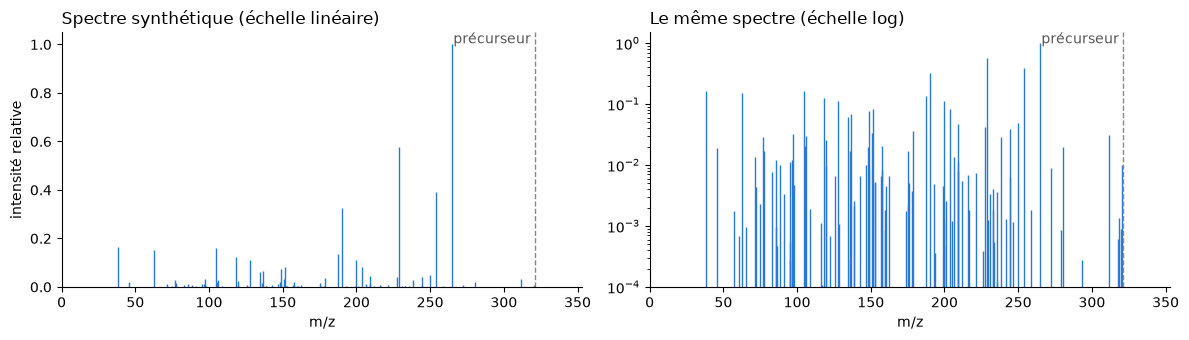

Spectre synthétique : 111 pics, dont 16 d'intensité au moins 0,05 ; précurseur à 321 m/z
Sur les 2 000 spectres : 227,438 pics, dont 80 % d'intensité inférieure à 0,05
Pic de base : à 61 % du précurseur en médiane, sur le précurseur lui-même (à 2 % près) pour 14 % des spectres


In [3]:
# Les 2 000 premiers spectres du fichier suffisent pour un aperçu : on ne lit pas tous les pics
pf = pq.ParquetFile(TRAIN_PATH)
first = next(pf.iter_batches(batch_size=2000, columns=COLUMNS + ["ms2_mzs", "ms2_normalized_intensities"])).to_pandas()

def peak_distributions(spectra):
    """Position (m/z / precursor_mz) et log10 de l'intensité des pics de tous les spectres, mis en commun.

    Renvoie à part la position du pic de base (intensité 1) de chaque spectre, puis celles des autres pics.
    """
    base, pos, logint = [], [], []
    for mzs, ints, prec in zip(spectra["ms2_mzs"], spectra["ms2_normalized_intensities"], spectra["precursor_mz"]):
        top = np.argmax(ints)
        others = np.arange(len(mzs)) != top
        base.append(mzs[top] / prec)
        pos.append(mzs[others] / prec)
        logint.append(np.log10(ints[others]))
    return np.array(base), np.concatenate(pos), np.clip(np.concatenate(logint), -4, 0)

def synthetic_spectrum(base, pos, logint, n_peaks, precursor, rng):
    """Spectre fabriqué : un pic de base placé comme les pics de base, et n_peaks - 1 pics tirés dans
    l'histogramme 2D (position, intensité) des autres pics. Il ne reproduit aucun spectre réel."""
    pos_edges = np.linspace(0, 1.02, 52)  # cases de 2 % du précurseur
    int_edges = np.linspace(-4, 0, 41)  # cases de 0,1 en log10 de l'intensité
    counts, _, _ = np.histogram2d(pos, logint, bins=[pos_edges, int_edges])
    cells = rng.choice(counts.size, size=n_peaks - 1, p=counts.ravel() / counts.sum())
    i, j = np.unravel_index(cells, counts.shape)
    rel = rng.uniform(pos_edges[i], pos_edges[i + 1])
    intensity = 10 ** rng.uniform(int_edges[j], int_edges[j + 1])
    base_counts, _ = np.histogram(base, bins=pos_edges)
    k = rng.choice(len(base_counts), p=base_counts / base_counts.sum())
    rel = np.append(rel, rng.uniform(pos_edges[k], pos_edges[k + 1]))
    return rel * precursor, np.append(intensity, 1.0)

peak_base, peak_pos, peak_logint = peak_distributions(first)
median_precursor = first["precursor_mz"].median()
synth_mz, synth_int = synthetic_spectrum(peak_base, peak_pos, peak_logint, int(first["num_peaks"].median()),
                                         median_precursor, np.random.default_rng(SEED))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.vlines(synth_mz, 1e-4 if scale == "log" else 0, synth_int, color="#2a78d6", linewidth=1)
    ax.axvline(median_precursor, color="#888888", linestyle="--", linewidth=1)
    ax.text(median_precursor, 1, "précurseur ", transform=ax.get_xaxis_transform(), ha="right", va="top",
            color="#555555")
    ax.set_yscale(scale)
    ax.set_ylim(*((1e-4, 1.5) if scale == "log" else (0, 1.05)))
    ax.set_xlim(0, median_precursor * 1.1)
    ax.set_xlabel("m/z")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("intensité relative")
axes[0].set_title("Spectre synthétique (échelle linéaire)", loc="left")
axes[1].set_title("Le même spectre (échelle log)", loc="left")
plt.tight_layout()
save_figure(fig, "spectre_synthetique")
plt.show()

n_all = len(peak_base) + len(peak_pos)
print(f"Spectre synthétique : {len(synth_mz)} pics, dont {np.sum(synth_int >= 0.05)} d'intensité au moins 0,05 ; "
      f"précurseur à {median_precursor:.0f} m/z")
print(f"Sur les 2 000 spectres : {n_all:,} pics, dont {100 * np.sum(peak_logint < np.log10(0.05)) / n_all:.0f} % "
      f"d'intensité inférieure à 0,05")
print(f"Pic de base : à {100 * np.median(peak_base):.0f} % du précurseur en médiane, "
      f"sur le précurseur lui-même (à 2 % près) pour {100 * np.mean(peak_base > 0.98):.0f} % des spectres")

### Provenance des spectres

Le train réunit plusieurs bibliothèques de spectres (`ingest_lib`), mesurées dans des laboratoires et sur des appareils différents. Le graphique compte les spectres de chacune, et le tableau ajoute leur part et leur nombre de molécules.

Constat : enveda-180 fournit 45,4 % des spectres et 182 941 molécules. Les quatre plus grosses bibliothèques réunissent 88,6 % des spectres.

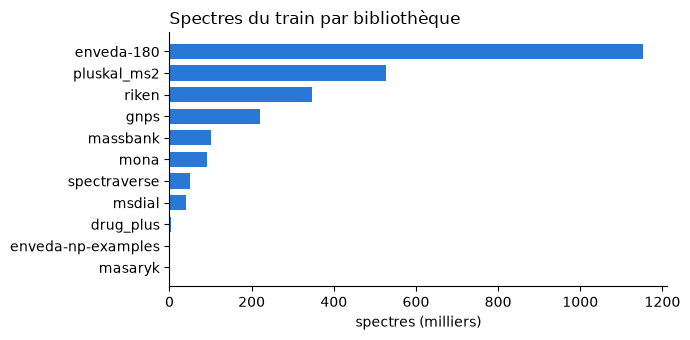

,spectres,% des spectres,molécules
ingest_lib,,,
enveda-180,1153785,45.4,182941
pluskal_ms2,527581,20.8,46821
riken,347171,13.7,15892
gnps,220849,8.7,45750
massbank,101727,4.0,9180
mona,92416,3.6,11681
spectraverse,50933,2.0,9631
msdial,40765,1.6,9127
drug_plus,2545,0.1,2539


In [4]:
counts = train["ingest_lib"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(counts.index, counts.values / 1e3, color="#2a78d6", height=0.7)
ax.set_xlabel("spectres (milliers)")
ax.set_title("Spectres du train par bibliothèque", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save_figure(fig, "provenance_spectres")
plt.show()

molecules = train.groupby("ingest_lib")["inchikey14"].nunique()
pd.DataFrame({"spectres": counts, "% des spectres": (counts / len(train) * 100).round(1),
              "molécules": molecules}).sort_values("spectres", ascending=False)

### Valeurs manquantes

Dans `instrument_type`, certains spectres portent un texte (`"nan"`, `"N/A"` ou une chaîne vide) à la place d'une valeur manquante, et `isna()` ne les voit pas. On les convertit d'abord. Le tableau donne ensuite la part de valeurs manquantes des colonnes que nous utilisons, dans le train et dans le test.

Constat : 1 645 faux manquants convertis. Dans le train, `instrument_type` manque pour 1,37 % des spectres et `collision_energy_ev` pour 13,29 %. Le test fourni n'a aucune valeur manquante.

In [5]:
FAKE_NA = ["nan", "N/A", ""]  # textes mis à la place d'une valeur manquante
n_fake = train["instrument_type"].isin(FAKE_NA).sum()
train["instrument_type"] = train["instrument_type"].mask(train["instrument_type"].isin(FAKE_NA))
print(f"Faux manquants convertis dans instrument_type : {n_fake:,}")

cols = ["adduct", "ionization_mode", "precursor_mz", "instrument_type", "collision_energy_ev"]
display(pd.DataFrame({"train (%)": train[cols].isna().mean() * 100,
                      "test (%)": test[cols].isna().mean() * 100}).round(2))

Faux manquants convertis dans instrument_type : 1,645


,train (%),test (%)
adduct,0.00,0.0
ionization_mode,0.00,0.0
precursor_mz,0.00,0.0
instrument_type,1.37,0.0
collision_energy_ev,13.29,0.0


La carte ci-dessous couvre les 18 colonnes du train. Les colonnes hors pics sont lues une par une ; pour les deux colonnes de pics, trop lourdes, on lit le nombre de valeurs nulles dans les métadonnées du fichier. Chaque ligne est une bibliothèque, puis viennent le train entier et le test fourni ; « absente » signale une colonne que le test n'a pas.

Constat : cinq colonnes ont des valeurs manquantes, et tout dépend de la bibliothèque. enveda-180 et enveda-np-examples sont complètes, alors que sept bibliothèques ne renseignent jamais `base_peak_intensity`. Les pics n'ont aucune valeur nulle.

ms2_mzs : 0 valeur nulle
ms2_normalized_intensities : 0 valeur nulle


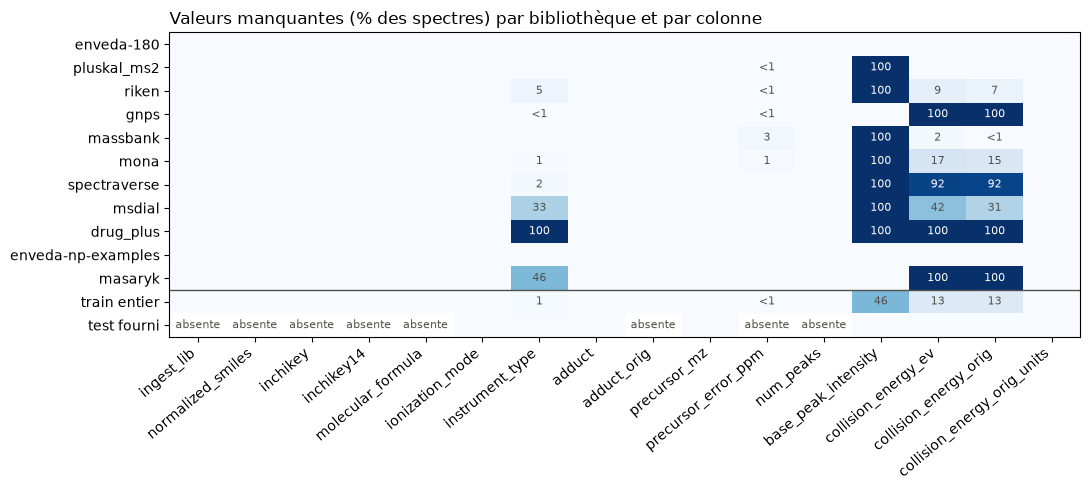

In [6]:
pf = pq.ParquetFile(TRAIN_PATH)
peak_cols = ["ms2_mzs", "ms2_normalized_intensities"]
other_cols = [c for c in pf.schema_arrow.names if c not in peak_cols]

# Colonnes hors pics : lues une par une, pour ne jamais tout charger en mémoire
missing = pd.DataFrame({c: (train[c] if c in train else pd.read_parquet(TRAIN_PATH, columns=[c])[c]).isna()
                        for c in other_cols})
# Pics : trop lourds à lire, on compte les valeurs nulles dans les métadonnées du fichier
meta = pf.metadata
for c in peak_cols:
    i = [meta.schema.column(k).path.split(".")[0] for k in range(meta.num_columns)].index(c)
    print(f"{c} : {sum(meta.row_group(g).column(i).statistics.null_count for g in range(meta.num_row_groups))} valeur nulle")

order = train["ingest_lib"].value_counts().index
table = (missing.groupby(train["ingest_lib"]).mean() * 100).loc[order]
table.loc["train entier"] = missing.mean() * 100
table.loc["test fourni"] = test.isna().mean() * 100  # NaN si la colonne n'existe pas dans le test

fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow(table.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=100, aspect="auto")
for (i, j), v in np.ndenumerate(table.to_numpy(dtype=float)):
    label = "absente" if np.isnan(v) else (f"{v:.0f}" if v >= 0.5 else ("<1" if v > 0 else ""))
    ax.text(j, i, label, ha="center", va="center", fontsize=8, color="white" if v > 50 else "#52514e")
ax.set_xticks(range(table.shape[1]), table.columns, rotation=40, ha="right")
ax.set_yticks(range(table.shape[0]), table.index)
ax.axhline(len(order) - 0.5, color="#52514e", linewidth=1)
ax.set_title("Valeurs manquantes (% des spectres) par bibliothèque et par colonne", loc="left")
plt.tight_layout()
save_figure(fig, "valeurs_manquantes")
plt.show()

### Peut-on imputer les valeurs manquantes ?

On teste deux colonnes : `base_peak_intensity` (en log10, car elle varie sur plusieurs ordres de grandeur) et `collision_energy_ev` (la moyenne de la liste d'énergies). Les essais portent sur 500 000 spectres tirés au hasard, pour rester rapides. Les entrées des imputeurs n'utilisent que des colonnes présentes dans le test ; `instrument_type` est regroupé en familles d'appareils, car ses libellés sont très hétérogènes.

Constat : timsTOF (226 717 spectres), Orbitrap/FT (187 309) et QTOF/TOF (67 209) dominent l'échantillon. 6 870 spectres n'ont pas d'instrument (« Inconnu »).

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Familles d'instruments : la première dont le motif apparaît dans le libellé l'emporte
INSTRUMENT_FAMILIES = [
    ("timsTOF", r"tims"),
    ("Orbitrap/FT", r"orbitrap|exactive|qehf|ft\b|qft|itft|hybrid ft"),
    ("QTOF/TOF", r"tof|maxis|impact|synapt"),
    ("Trappe ionique", r"ion trap|iontrap|\blit\b|qit|ltq|-it\b"),
    ("Quadripôle", r"qqq|qq\b|quattro|-q\b"),
]

def instrument_family(s):
    """Famille de chaque libellé d'instrument ; "Inconnu" s'il manque, "Autre" s'il n'est d'aucune famille."""
    lower = s.str.lower()
    family = pd.Series("Autre", index=s.index).mask(s.isna(), "Inconnu")
    for name, pattern in reversed(INSTRUMENT_FAMILIES):
        family = family.mask(lower.str.contains(pattern, regex=True, na=False), name)
    return family

sample = train.sample(500_000, random_state=SEED)
top_adducts = train["adduct"].value_counts().index[:15]
X = pd.DataFrame({
    "precursor_mz": sample["precursor_mz"],
    "log_num_peaks": np.log10(sample["num_peaks"]),
    "mode": sample["ionization_mode"].astype("category"),
    "adduct": sample["adduct"].where(sample["adduct"].isin(top_adducts), "autre").astype("category"),
    "instrument": instrument_family(sample["instrument_type"]).astype("category"),
})
bpi = pd.read_parquet(TRAIN_PATH, columns=["base_peak_intensity"])["base_peak_intensity"]
y_bpi = np.log10(bpi.loc[sample.index])
y_ce = sample["collision_energy_ev"].dropna().map(np.mean).reindex(sample.index)  # moyenne de la liste d'énergies
X["instrument"].value_counts()

instrument
timsTOF           226717
Orbitrap/FT       187309
QTOF/TOF           67209
Quadripôle          7087
Inconnu             6870
Trappe ionique      4734
Autre                 74
Name: count, dtype: int64

On masque des valeurs **observées**, on les prédit, et on mesure l'erreur absolue moyenne (MAE, *mean absolute error*) sur les $n$ valeurs masquées :

$$\mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

où $y_i$ est la vraie valeur et $\hat{y}_i$ la valeur imputée. Pour `collision_energy_ev`, la MAE est en eV. Pour `base_peak_intensity`, $y$ est le log10 de l'intensité : une MAE de 1 correspond à une erreur d'un facteur 10 (en moyenne géométrique).

Deux masquages :
- au hasard, 20 % des valeurs ;
- une bibliothèque entière à la fois, ce qui reproduit les vrais manques, où une bibliothèque ne renseigne jamais la colonne.

Trois imputeurs, du plus simple au plus riche : la médiane globale, la médiane par famille d'instrument et mode, et un gradient boosting. La cellule prend une dizaine de secondes.

Constat :
- pour `base_peak_intensity`, le gradient boosting a une MAE de 0,68 quand on masque au hasard, soit une erreur d'un facteur 10^0,68 ≈ 5. Quand on cache gnps, sa MAE monte à 1,95, soit un facteur 90 environ, et aucun imputeur ne fait mieux que la médiane globale (1,93) ;
- pour `collision_energy_ev`, la médiane globale est la plus mauvaise sur tous les masquages. La médiane par instrument et mode a la plus petite MAE sur enveda-180 (8,99 eV) et pluskal_ms2 (12,70 eV), et le gradient boosting gagne sur les autres, avec des écarts de MAE de 1 à 4 eV.

In [8]:
def imputation_trial(X, y, libs):
    """Erreur absolue moyenne de trois imputeurs sur des valeurs observées que l'on masque."""
    observed = y.notna()
    masks = {"au hasard (20 %)": observed & (np.random.default_rng(SEED).random(len(y)) < 0.2)}
    for lib, n in libs[observed].value_counts().items():
        if n >= 1000:
            masks[f"bibliothèque {lib}"] = observed & (libs == lib)
    rows = []
    for name, masked in masks.items():
        fit = observed & ~masked  # les imputeurs n'apprennent que sur les valeurs restées visibles
        median = y[fit].median()
        by_group = y[fit].groupby([X.loc[fit, "instrument"], X.loc[fit, "mode"]], observed=True).median()
        group_pred = X[masked].join(by_group.rename("pred"), on=["instrument", "mode"])["pred"].fillna(median)
        model = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SEED)
        model_pred = model.fit(X[fit], y[fit]).predict(X[masked])
        rows.append({"masquage": name, "valeurs masquées": masked.sum(),
                     "médiane globale": (y[masked] - median).abs().mean(),
                     "médiane par instrument et mode": (y[masked] - group_pred).abs().mean(),
                     "gradient boosting": (y[masked] - model_pred).abs().mean()})
    return pd.DataFrame(rows).set_index("masquage").round(2)

libs = sample["ingest_lib"]
print("base_peak_intensity : erreur absolue moyenne en log10 (1 = un facteur 10)")
display(imputation_trial(X, y_bpi, libs))
print("collision_energy_ev : erreur absolue moyenne en eV")
display(imputation_trial(X, y_ce, libs))

base_peak_intensity : erreur absolue moyenne en log10 (1 = un facteur 10)


,valeurs masquées,médiane globale,médiane par instrument et mode,gradient boosting
masquage,,,,
au hasard (20 %),54101,1.08,0.99,0.68
bibliothèque enveda-180,226492,1.11,0.91,0.81
bibliothèque gnps,43682,1.93,2.06,1.95


collision_energy_ev : erreur absolue moyenne en eV


,valeurs masquées,médiane globale,médiane par instrument et mode,gradient boosting
masquage,,,,
au hasard (20 %),87040,13.88,12.22,11.53
bibliothèque enveda-180,226492,17.74,8.99,10.69
bibliothèque pluskal_ms2,104410,16.83,12.70,14.12
bibliothèque riken,62145,21.36,20.78,19.38
bibliothèque massbank,19651,24.56,23.91,22.61
bibliothèque mona,15017,17.77,16.59,12.64
bibliothèque msdial,4721,15.54,14.62,12.83


### Une formule pour une partie des énergies manquantes

Certaines bibliothèques donnent l'énergie de collision en NCE (énergie normalisée, en %) dans `collision_energy_orig`. Elle se convertit en eV par la formule **eV = NCE × precursor_mz / 500**, arrondie au dixième : une NCE de 30 % vaut 30 eV pour un précurseur à 500 m/z, et 60 eV à 1 000 m/z. Nous n'avons pas trouvé de source publiée pour cette formule : la cellule la vérifie donc sur les spectres qui ont les deux valeurs, puis l'applique aux énergies manquantes. Elle crée la colonne `ce_mean`, la moyenne de la liste d'énergies de chaque spectre.

Constat : sur les 342 722 spectres qui ont les deux valeurs, la formule est exacte pour 99,99 %. Elle retrouve 11 064 des 337 443 énergies manquantes ; les 326 379 restantes sont imputées à la section 8.

In [9]:
raw_ce = pd.read_parquet(TRAIN_PATH, columns=["collision_energy_orig", "collision_energy_orig_units"])

# Énergie NCE simple ("35" ou "35%") ; les plages ("30->50%") et les listes ne sont pas converties
text = raw_ce["collision_energy_orig"].str.strip().str.rstrip("%")
nce = pd.to_numeric(text.where(text.str.fullmatch(r"\d+(\.\d+)?", na=False)), errors="coerce")
nce = nce.where(raw_ce["collision_energy_orig_units"] == "NCE")
ev_formula = (nce * train["precursor_mz"] / 500).round(1)

# Une seule énergie par spectre : la moyenne de la liste
train["ce_mean"] = train["collision_energy_ev"].map(lambda v: np.mean(v) if v is not None and len(v) else np.nan)
single = train["collision_energy_ev"].map(lambda v: v is not None and len(v) == 1)

check = ev_formula.notna() & single
exact = (ev_formula[check] - train.loc[check, "ce_mean"]).abs() <= 0.051
print(f"Spectres qui ont l'énergie en NCE et en eV : {check.sum():,}, formule exacte pour {exact.mean():.2%}")

fill = train["ce_mean"].isna() & ev_formula.notna()
train.loc[fill, "ce_mean"] = ev_formula[fill]
print(f"Énergies manquantes : {fill.sum() + train['ce_mean'].isna().sum():,}, "
      f"retrouvées par la formule : {fill.sum():,}, restantes : {train['ce_mean'].isna().sum():,}")

Spectres qui ont l'énergie en NCE et en eV : 342,722, formule exacte pour 99.99%
Énergies manquantes : 337,443, retrouvées par la formule : 11,064, restantes : 326,379


### Décision pour chaque colonne incomplète

On garde tous les spectres. Retirer ceux qui ont une valeur manquante supprimerait des bibliothèques entières, comme gnps, qui n'a aucune énergie de collision.

| Colonne | Manquants (train) | Décision | Raison |
|---|---|---|---|
| `base_peak_intensity` | 46 % | colonne écartée | Sept bibliothèques ne la renseignent jamais, donc son absence révèle surtout la bibliothèque. Les essais ci-dessus échouent quand on masque une bibliothèque entière. Surtout, c'est une intensité absolue : elle dépend de la quantité de molécule injectée, qu'on ne connaît pas, et des conditions de mesure, comme la suppression d'ionisation par les autres composés de l'échantillon (Annesley, 2003). Les bibliothèques publiques réunissent des spectres mesurés dans des conditions non standardisées (Horai *et al.*, 2010). La structure joue aussi, par l'efficacité d'ionisation, qui s'étale sur six ordres de grandeur d'un composé à l'autre dans les mêmes conditions (Oss *et al.*, 2010), mais on ne peut pas la séparer de la quantité injectée. Les intensités des pics sont déjà relatives (le pic le plus intense vaut 1) : on garde celles-là. |
| `collision_energy_ev` | 13 % | formule NCE → eV quand le texte d'origine le permet, puis médiane par famille d'instrument et mode, avec une variable indicatrice `ce_manquante` | La formule est exacte, mais ne s'applique qu'à une petite partie des manques. La médiane par groupe fait mieux que la médiane globale sur tous les masquages et reste proche du gradient boosting, pour un code bien plus simple. L'indicatrice vaut 1 quand l'énergie vient de la médiane. |
| `collision_energy_orig` | 13 % | sert seulement à la formule NCE → eV | C'est le texte d'origine de l'énergie, qui n'est pas une feature en soi. |
| `instrument_type` | 1 % | catégorie « Inconnu » | Les manques sont rares, et une catégorie à part évite de deviner l'appareil. |
| `precursor_error_ppm` | moins de 1 % | colonne écartée | Elle est calculée à partir de la vraie structure et n'existe pas dans le test : l'utiliser serait une fuite. |

Les médianes seront calculées sur les spectres d'entraînement seulement, après le split, puis appliquées à la validation et au test. Ces choix servent surtout à l'entraînement, puisque le test fourni n'a aucune valeur manquante.

Sources :
- T. M. Annesley, « Ion suppression in mass spectrometry », *Clinical Chemistry*, 49(7), 1041-1044, 2003 (PMID 12816898).
- H. Horai *et al.*, « MassBank: a public repository for sharing mass spectral data for life sciences », *Journal of Mass Spectrometry*, 45(7), 703-714, 2010 (PMID 20623627).
- M. Oss, A. Kruve, K. Herodes et I. Leito, « Electrospray ionization efficiency scale of organic compounds », *Analytical Chemistry*, 82(7), 2865-2872, 2010 (PMID 20218595).

## 3. Nettoyage et split

Certaines étiquettes du train sont fausses : un adduct illisible, un adduct de charge opposée au mode d'ionisation, ou une masse qui ne correspond pas à la structure annoncée. On ne supprime aucune ligne. On calcule deux filtres, car l'entraînement et l'évaluation n'ont pas droit aux mêmes informations :
- `keep` : le spectre peut servir à l'**entraînement**. Toutes les règles comptent, y compris l'erreur de masse, qui utilise la vraie structure : pendant l'entraînement, on la connaît ;
- `query_ok` : le spectre peut servir à l'**évaluation**, parmi les spectres d'une molécule de validation dont on cherche la structure (une requête, définie à la section 4). On le traite comme un spectre du test, dont la structure est inconnue : seules comptent les règles qui s'en passent. Écarter aussi les spectres que seule la vraie structure permet de repérer rendrait la validation plus facile que le test, où on ne pourrait pas les repérer, et son score trop optimiste.

### Lire les adducts

Pour M la molécule qu'on cherche à prédire, un adduct s'écrit `[nM ± groupes]z±` : n molécules M, des groupes ajoutés ou perdus, puis la charge. La fonction `parse_adduct` lit ce texte et le découpe en (n, masse ajoutée ou perdue, charge signée), avec les masses monoisotopiques de RDKit (celle de l'isotope le plus courant de chaque élément) : par exemple, `[M+Na]+` donne (1, +22,990 Da, +1). Le même découpage servira au calcul de la masse neutre.

In [10]:
import re

from rdkit import Chem
from rdkit.Chem import Descriptors

PERIODIC_TABLE = Chem.GetPeriodicTable()
ELECTRON_MASS = 0.000548579909  # Da
ADDUCT_RE = re.compile(r"\[(\d*)M((?:[+-]\d*[A-Z][A-Za-z0-9]*)*)\](\d*)([+-])")

def formula_mass(formula):
    """Masse monoisotopique d'une formule brute ("H2O") ; erreur si elle n'est pas lisible."""
    if not re.fullmatch(r"(?:[A-Z][a-z]?\d*)+", formula):
        raise ValueError(formula)
    return sum(PERIODIC_TABLE.GetMostCommonIsotopeMass(el) * int(n or 1)
               for el, n in re.findall(r"([A-Z][a-z]?)(\d*)", formula))

def parse_adduct(adduct):
    """(n molécules M, masse ajoutée ou perdue en Da, charge signée), ou None si l'adduct n'est pas lisible."""
    match = ADDUCT_RE.fullmatch(adduct)
    if match is None:
        return None
    n_mol, terms, charge, sign = match.groups()
    try:
        delta = sum((1 if s == "+" else -1) * int(k or 1) * formula_mass(f)
                    for s, k, f in re.findall(r"([+-])(\d*)([A-Z][A-Za-z0-9]*)", terms))
    except (ValueError, RuntimeError):
        return None
    return int(n_mol or 1), delta, int(charge or 1) * (1 if sign == "+" else -1)

adducts = pd.DataFrame([(a, parse_adduct(a)) for a in train["adduct"].unique()], columns=["adduct", "parsed"])
print("Adducts non lisibles :", adducts.loc[adducts["parsed"].isna(), "adduct"].tolist())

Adducts non lisibles : ['[Cat]2+']


### Deux règles sans la structure

- Charge contre mode : un ion négatif (`[M-H]-`) ne peut pas être mesuré en mode positif, ni l'inverse. L'adduct ou le mode est donc mal étiqueté.
- Adduct douteux : les précurseurs `[M-CH3]-` sont dispersés et ne correspondent à aucune formule, d'après l'analyse de la masse neutre faite plus tôt dans le projet.

Constat : 6 087 spectres ont une charge opposée au mode, surtout des `[M-H]-` en mode positif (5 258) et des `[M+H]+` en mode négatif (675). 619 spectres sont en `[M-CH3]-` et 15 ont un adduct illisible.

In [11]:
params = {a: p for a, p in zip(adducts["adduct"], adducts["parsed"]) if p is not None}
charge = train["adduct"].map(lambda a: params[a][2] if a in params else np.nan)
expected = train["ionization_mode"].map({"positive": 1, "negative": -1})

rules = pd.DataFrame({
    "adduct_inconnu": charge.isna(),
    "charge_contre_mode": charge.notna() & (np.sign(charge) != expected),
    "adduct_douteux": train["adduct"] == "[M-CH3]-",
})
display(pd.crosstab(train.loc[rules["charge_contre_mode"], "adduct"],
                    train.loc[rules["charge_contre_mode"], "ionization_mode"]).head(10))
rules.sum().rename("spectres").to_frame()

ionization_mode,negative,positive
adduct,,
[M+Cl]-,0,18
[M+H3O]+,3,0
[M+H]+,675,0
[M+NH4]+,10,0
[M+Na-H2]-,0,3
[M+Na]+,18,0
[M-H2O+H]+,70,0
[M-H2O-H]-,0,5
[M-H2]2-,0,1


,spectres
adduct_inconnu,15
charge_contre_mode,6087
adduct_douteux,619


### L'erreur de masse

On compare la masse neutre déduite du précurseur et de l'adduct à la masse exacte de la vraie structure (RDKit). Un grand écart signale une étiquette fausse : mauvais adduct ou mauvaise structure. Cette règle utilise la structure, donc elle ne filtre que l'entraînement.

On recalcule cet écart au lieu de lire `precursor_error_ppm` : le premier tableau compare les médianes par adduct, et la colonne fournie paraît décalée pour certains adducts. L'histogramme montre la distribution des écarts, et le dernier tableau le nombre de spectres au-dessus de plusieurs seuils. La cellule prend environ 30 s.

Constat : notre écart médian va de -0,04 à 0,82 ppm sur les adducts courants, contre 0,87 à 2,72 ppm pour la colonne fournie. 25 053 spectres (0,99 % du train) dépassent 0,75 Da. Entre 0,5 et 1 Da, ce nombre bouge à peine (de 25 344 à 24 695) : les étiquettes fausses sont bien séparées des petites erreurs de mesure.

,precursor_error_ppm fourni,notre écart (ppm)
adduct,,
[M+H]+,1.37,0.82
[M-H]-,1.87,0.07
[M+Na]+,2.72,-0.04
[2M+Na]+,0.87,0.79


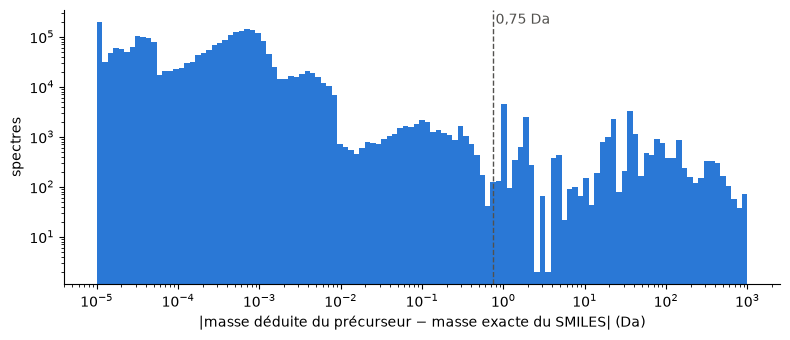

,spectres au-dessus,% du train
seuil (Da),,
0.01,53212,2.10
0.10,37894,1.49
0.50,25344,1.00
0.75,25053,0.99
1.00,24695,0.97
5.00,16112,0.63
50.00,6249,0.25


In [12]:
# Masse neutre : |z| × m/z = n × M + delta − z × m_e, d'où M = (|z| × m/z − delta + z × m_e) / n
p = train["adduct"].map(params)
n_mol, delta, z = (p.map(lambda t: t[i] if isinstance(t, tuple) else np.nan) for i in range(3))
train["neutral_mass"] = (z.abs() * train["precursor_mz"] - delta + z * ELECTRON_MASS) / n_mol

# Masse exacte de la vraie structure, calculée une fois par SMILES distinct (environ une minute)
smiles = train["normalized_smiles"].unique()
exact = {s: Descriptors.ExactMolWt(m) for s in smiles if (m := Chem.MolFromSmiles(s)) is not None}
train["mass_error_da"] = train["neutral_mass"] - train["normalized_smiles"].map(exact)

ppm = pd.read_parquet(TRAIN_PATH, columns=["precursor_error_ppm"])["precursor_error_ppm"]
ours_ppm = train["mass_error_da"] / train["neutral_mass"] * 1e6
display(pd.DataFrame({"precursor_error_ppm fourni": ppm, "notre écart (ppm)": ours_ppm})
        .groupby(train["adduct"]).median().loc[["[M+H]+", "[M-H]-", "[M+Na]+", "[2M+Na]+"]].round(2))

err = train["mass_error_da"].abs().clip(1e-5, 999)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(err.dropna(), bins=np.logspace(-5, 3, 120), color="#2a78d6")
ax.axvline(0.75, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.8, ax.get_ylim()[1] * 0.9, "0,75 Da", color="#52514e")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("|masse déduite du précurseur − masse exacte du SMILES| (Da)"); ax.set_ylabel("spectres")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); save_figure(fig, "erreur_de_masse"); plt.show()

thresholds = [0.01, 0.1, 0.5, 0.75, 1, 5, 50]
pd.DataFrame({"seuil (Da)": thresholds, "spectres au-dessus": [(err > t).sum() for t in thresholds],
              "% du train": [round((err > t).mean() * 100, 2) for t in thresholds]}).set_index("seuil (Da)")

### Les filtres `keep` et `query_ok`

Le seuil d'erreur de masse est un paramètre de `keep_mask`. On garde 0,75 Da, pour les raisons données plus bas (« Décisions de nettoyage »). Les requêtes de validation ne dépendent jamais de ce seuil.

Constat : le seuil de 0,75 Da garde 98,88 % des spectres pour l'entraînement, celui de 0,1 Da 98,42 %. gnps (4,80 % écartés) et riken (3,97 %) sont les plus touchées ; enveda-180 et pluskal_ms2 ne perdent rien. Côté requêtes, riken perd le plus, avec 1,55 %.

In [13]:
MASS_THRESHOLD = 0.75                     # Da, seuil retenu par défaut
CLEANING_THRESHOLDS = [None, 5, 1, 0.75, 0.1]  # seuils à comparer sur le MRR@25 en validation (None = pas de filtre)

def keep_mask(threshold=MASS_THRESHOLD):
    """Spectres fiables pour l'entraînement : aucune règle, et erreur de masse sous le seuil (None = pas de seuil)."""
    mass_ok = True if threshold is None else ~(train["mass_error_da"].abs() > threshold)
    return ~rules.any(axis=1) & mass_ok

# Requêtes de validation : seulement les règles qui n'utilisent pas la vraie structure
train["query_ok"] = ~rules.any(axis=1)
train["keep"] = keep_mask()

display(pd.DataFrame({"seuil (Da)": [str(t) for t in CLEANING_THRESHOLDS],
                      "spectres gardés pour l'entraînement (%)": [round(keep_mask(t).mean() * 100, 2) for t in CLEANING_THRESHOLDS]})
        .set_index("seuil (Da)"))
by_lib = pd.DataFrame({"écartés de l'entraînement (%)": (~train["keep"]).groupby(train["ingest_lib"]).mean() * 100,
                       "écartés des requêtes (%)": (~train["query_ok"]).groupby(train["ingest_lib"]).mean() * 100})
by_lib.round(2).sort_values("écartés de l'entraînement (%)", ascending=False)

,spectres gardés pour l'entraînement (%)
seuil (Da),
None,99.74
5,99.18
1,98.90
0.75,98.88
0.1,98.42


,écartés de l'entraînement (%),écartés des requêtes (%)
ingest_lib,,
gnps,4.80,0.25
riken,3.97,1.55
drug_plus,3.50,0.00
mona,2.27,0.42
massbank,1.64,0.40
msdial,0.16,0.00
spectraverse,0.01,0.00
enveda-np-examples,0.00,0.00
enveda-180,0.00,0.00


### Décisions de nettoyage

| Règle | Ce qu'elle repère | Utilise la structure ? | Filtre |
|---|---|---|---|
| adduct inconnu | adduct illisible (`[Cat]2+`) : pas de masse neutre | non | `keep` et `query_ok` |
| charge contre mode | charge de l'adduct opposée au mode d'ionisation | non | `keep` et `query_ok` |
| adduct douteux | `[M-CH3]-` | non | `keep` et `query_ok` |
| erreur de masse | écart de plus de 0,75 Da entre la masse déduite et la masse exacte | oui | `keep` seulement |

Pourquoi 0,75 Da par défaut :
- une erreur d'adduct décale la masse d'au moins un atome d'hydrogène, soit 1,008 Da ; Na pris pour H fait 21,98 Da ;
- un précurseur noté à l'unité près, sur un appareil à basse résolution, s'écarte d'au plus 0,5 Da ;
- les appareils à haute résolution se trompent de quelques ppm, soit environ 0,001 Da pour une molécule de 300 Da : moins de 2 ppm avec un étalon interne et moins de 5 ppm avec un étalonnage externe sur Orbitrap (Makarov *et al.*, 2006), quelques ppm sur les appareils à temps de vol (Kind et Fiehn, 2006).

Un seuil en daltons, contrairement à un seuil en ppm, ne dépend pas de la taille de la molécule. Des tests précédents, externes au notebook, ont comparé plusieurs seuils (`CLEANING_THRESHOLDS`) : ils donnaient le même MRR@25 (0,398 pour le kNN sans filtre, à 0,75 Da et à 0,1 Da) : on garde 0,75 Da.

Sources :
- A. Makarov *et al.*, « Performance evaluation of a hybrid linear ion trap/orbitrap mass spectrometer », *Analytical Chemistry*, 78(7), 2113-2120, 2006 (PMID 16579588).
- T. Kind et O. Fiehn, « Metabolomic database annotations via query of elemental compositions: mass accuracy is insufficient even at less than 1 ppm », *BMC Bioinformatics*, 7, 234, 2006 (PMID 16646969).

### Le split par molécule

Pour l'instant, on ne travaille que sur le train. On le coupe selon les **molécules** (`inchikey14`), et non selon les spectres : tous les spectres d'une molécule vont du même côté. Un split par spectre mettrait des spectres d'une même molécule des deux côtés, et le modèle reconnaîtrait en validation des molécules déjà vues à l'entraînement. C'est une fuite, et le test caché ne la permet pas.

10 % des molécules vont en validation, et 2 000 d'entre elles forment le sous-ensemble `dev`, pour itérer vite. La graine est 42. 2 000 autres molécules de validation forment le sous-ensemble `confirmation` : elles ne servent qu'à la note finale (section 12), pour mesurer sans optimisme le score de réglages choisis sur `dev`. Elles sont tirées après `dev`, pour que `dev` reste celui des tests précédents, externes au notebook, et que leurs scores restent comparables. L'entraînement utilise le filtre `keep`, les requêtes de validation le filtre `query_ok`.

Constat : aucune molécule en commun. L'entraînement compte 2 261 657 spectres (247 314 molécules), la validation 251 813 spectres (27 578 molécules), dont 18 899 spectres pour les 2 000 molécules `dev` et 18 473 spectres pour les molécules `confirmation`. Celles-ci ne sont que 1 999 : l'une des 2 000 molécules tirées n'a aucun spectre utilisable comme requête. Chaque bibliothèque pèse autant des deux côtés, par exemple enveda-180 avec 45,4 % et 45,7 %.

In [14]:
VAL_FRACTION = 0.10     # part des molécules mises en validation
N_DEV = 2_000           # molécules de validation gardées pour itérer vite
N_CONFIRMATION = 2_000  # autres molécules de validation, réservées à la confirmation finale (section 12)

molecules = np.sort(train["inchikey14"].unique())  # trié : le tirage ne dépend pas de l'ordre du fichier
rng = np.random.default_rng(SEED)
val_molecules = rng.choice(molecules, size=round(len(molecules) * VAL_FRACTION), replace=False)
dev_molecules = rng.choice(np.sort(val_molecules), size=N_DEV, replace=False)
# Tirées après dev, pour que dev reste celui des tests précédents, externes au notebook
conf_molecules = rng.choice(np.setdiff1d(val_molecules, dev_molecules), size=N_CONFIRMATION, replace=False)

train["split"] = np.where(train["inchikey14"].isin(val_molecules), "val", "train")
train["dev"] = train["inchikey14"].isin(dev_molecules)
train["confirmation"] = train["inchikey14"].isin(conf_molecules)

shared = set(train.loc[train["split"] == "train", "inchikey14"]) & set(train.loc[train["split"] == "val", "inchikey14"])
print(f"Molécules à la fois en entraînement et en validation : {len(shared)}")

groups = {"entraînement (keep)": (train["split"] == "train") & train["keep"],
          "validation (query_ok)": (train["split"] == "val") & train["query_ok"],
          "dont dev": train["dev"] & train["query_ok"],
          "dont confirmation": train["confirmation"] & train["query_ok"]}
display(pd.DataFrame({name: {"spectres": m.sum(), "molécules": train.loc[m, "inchikey14"].nunique()}
                      for name, m in groups.items()}).T)

# Les bibliothèques doivent peser à peu près autant des deux côtés
(pd.crosstab(train["ingest_lib"], train["split"], normalize="columns") * 100).round(1).sort_values("train", ascending=False)

Molécules à la fois en entraînement et en validation : 0


,spectres,molécules
entraînement (keep),2261657,247314
validation (query_ok),251813,27578
dont dev,18899,2000
dont confirmation,18473,1999


split,train,val
ingest_lib,,
enveda-180,45.4,45.7
pluskal_ms2,20.7,21.1
riken,13.7,13.2
gnps,8.7,8.7
massbank,4.0,3.9
mona,3.6,3.7
spectraverse,2.0,1.9
msdial,1.6,1.6
drug_plus,0.1,0.1


## 4. Catalogue et filtre par masse

La molécule cherchée n'est pas forcément dans le jeu de données de la compétition : on peut avoir à identifier une molécule qu'aucun spectre du train ne montre. Un catalogue limité aux molécules du train ne pourrait jamais la proposer. On y ajoute donc COCONUT (Sorokina *et al.*, 2021 ; Chandrasekhar *et al.*, 2025), une bibliothèque ouverte de produits naturels (version de novembre 2026), qui apporte des structures absentes du train. Deux catalogues sont comparés :
- COCONUT + train/val, le catalogue principal : la bonne réponse y est toujours, mais au milieu de nombreux candidats de même masse ;
- COCONUT seule : elle simule une molécule absente du jeu de données, qu'on ne peut retrouver que dans une bibliothèque externe. Si la bonne structure n'est pas dans COCONUT, aucun modèle ne peut la trouver.

Une structure est identifiée par les 14 premiers caractères de son InChIKey, comme dans la métrique : les stéréoisomères de COCONUT sont confondus. Une molécule du train garde son SMILES du train. La masse exacte de chaque structure est calculée par RDKit, comme à la section 3. COCONUT est lu sous sa forme réduite, `externe/coconut.parquet`, fournie avec le dépôt ; sans elle, la table est recalculée depuis l'archive complète, en quelques minutes.

Constat : le catalogue principal compte 729 385 structures, de 1,0 à 7 855,7 Da. 479 685 viennent de COCONUT, et 275 810 sont les molécules de la compétition, dont 26 110 seulement figurent aussi dans COCONUT. Surtout, 9,6 % des molécules `dev` sont dans COCONUT : avec COCONUT seule, neuf molécules sur dix n'ont aucune chance d'être retrouvées.

Sources :
- M. Sorokina, P. Merseburger, K. Rajan, M. A. Yirik et C. Steinbeck, « COCONUT online: Collection of Open Natural Products database », *Journal of Cheminformatics*, 13, 2, 2021 (PMID 33423696).
- V. Chandrasekhar *et al.*, « COCONUT 2.0: a comprehensive overhaul and curation of the collection of open natural products database », *Nucleic Acids Research*, 53(D1), D634-D643, 2025 (PMID 39588778).

In [15]:
import zipfile

from rdkit import RDLogger
from rdkit.Chem import rdFingerprintGenerator

RDLogger.DisableLog("rdApp.*")  # COCONUT contient quelques SMILES que RDKit refuse : on les écarte sans message

# Molécules du train et de la validation : le premier SMILES rencontré représente la molécule
own = (train.drop_duplicates("inchikey14")[["inchikey14", "normalized_smiles"]]
       .rename(columns={"normalized_smiles": "smiles"})
       .assign(exact_mass=lambda d: d["smiles"].map(exact)))

# COCONUT réduit : une ligne par inchikey14, masse exacte calculée par RDKit. Fourni avec le dépôt (externe/) ;
# sinon, recalculé depuis l'archive complète (quelques minutes) et enregistré à cet endroit.
if COCONUT_TABLE.exists():
    coconut = pd.read_parquet(COCONUT_TABLE)
else:
    with zipfile.ZipFile(COCONUT_PATH) as z:
        coconut = pd.read_csv(z.open(z.namelist()[0]), usecols=["canonical_smiles", "standard_inchi_key"]).dropna()
    coconut = (coconut.assign(inchikey14=coconut["standard_inchi_key"].str[:14]).drop_duplicates("inchikey14")
               .rename(columns={"canonical_smiles": "smiles"})[["inchikey14", "smiles"]])
    coconut["exact_mass"] = [Descriptors.ExactMolWt(m) if (m := Chem.MolFromSmiles(s)) is not None else np.nan
                             for s in coconut["smiles"]]
    coconut = coconut.dropna().reset_index(drop=True)
    COCONUT_TABLE.parent.mkdir(exist_ok=True)
    coconut.to_parquet(COCONUT_TABLE)

# Catalogue principal : les molécules du train et de la validation, puis celles de COCONUT qui n'y sont pas
catalog = (pd.concat([own, coconut[~coconut["inchikey14"].isin(own["inchikey14"])]], ignore_index=True)
           .assign(coconut=lambda d: d["inchikey14"].isin(coconut["inchikey14"]))
           .sort_values("exact_mass", ignore_index=True))
cat_keys = catalog["inchikey14"].to_numpy()
cat_masses = catalog["exact_mass"].to_numpy()
cat_row = pd.Series(np.arange(len(catalog)), index=cat_keys)  # inchikey14 -> ligne du catalogue

dev_keys = train.loc[train["dev"], "inchikey14"].unique()
display(pd.Series({"catalogue principal (COCONUT + train/val)": len(catalog),
                   "dont structures de COCONUT (catalogue « COCONUT seule »)": int(catalog["coconut"].sum()),
                   "dont molécules du train et de la validation": len(own),
                   "molécules du train et de la validation présentes dans COCONUT": int(own["inchikey14"].isin(coconut["inchikey14"]).sum())},
                  name="structures").to_frame())
print(f"Molécules dev présentes dans COCONUT : {np.isin(dev_keys, coconut['inchikey14']).mean():.1%}")
print(f"Masses de {np.nanmin(cat_masses):.1f} à {np.nanmax(cat_masses):.1f} Da")

,structures
catalogue principal (COCONUT + train/val),729385
dont structures de COCONUT (catalogue « COCONUT seule »),479685
dont molécules du train et de la validation,275810
molécules du train et de la validation présentes dans COCONUT,26110


Molécules dev présentes dans COCONUT : 9.6%
Masses de 1.0 à 7855.7 Da


Une requête est une question posée au système : « voici les spectres d'une molécule, quelle est-elle ? ». Elle réunit les spectres `query_ok` d'une molécule de validation, dont on cache la structure ; le système classe des candidats, et le rang de la vraie structure donne la note de la requête. Regrouper les spectres par molécule n'est pas une fuite : le test fourni donne le même regroupement, par un identifiant anonyme (`molecule_id`), sans la structure, et la vraie structure ne sert ici qu'à noter le classement. C'est en revanche un léger biais optimiste : une requête `dev` compte 9,4 spectres en moyenne (18 899 pour 2 000 molécules), contre 3,0 dans le test fourni (1 213 pour 400), ce qui rend probablement sa masse et sa prédiction plus sûres. Il y a deux ensembles de requêtes : `dev`, qui sert à tous les choix, et `confirmation`, qui ne sert qu'à la note finale.

La masse neutre d'une requête est la médiane des masses neutres de ses spectres (calculées à la section 3), ce qui protège contre un spectre isolé mal étiqueté. Ses candidats sont les structures du catalogue dont la masse est proche, à ±10 ppm ou à ±20 ppm ; pour le catalogue « COCONUT seule », on ne garde que celles qui viennent de COCONUT. Le rappel du filtre est la part des molécules dont la bonne structure est parmi les candidats : c'est le plafond de tout le pipeline.

Constat : avec le catalogue principal à ±10 ppm, la bonne structure est parmi les candidats pour 98,6 % des molécules `dev` (98,8 % en confirmation), avec 91 candidats en médiane et 268 au 90e centile. À ±20 ppm, le rappel ne gagne que 0,3 point (98,9 %) pour presque deux fois plus de candidats (169 en médiane). Avec COCONUT seule, le rappel tombe à 8,9 % : c'est le plafond de tout modèle dans ce catalogue.

In [16]:
PPM_VALUES = [10, 20]          # tolérances du filtre par masse, comparées en validation
MAIN = "COCONUT + train/val"   # catalogue principal
CATALOGUES = {MAIN: np.ones(len(catalog), bool), "COCONUT seule": catalog["coconut"].to_numpy()}  # lignes gardées

def make_queries(molecule_mask):
    """Une requête par molécule : ses spectres query_ok, et la médiane de leurs masses neutres."""
    return (train[molecule_mask & train["query_ok"]].groupby("inchikey14")
            .agg(neutral_mass=("neutral_mass", "median")).reset_index())

def candidates(mass, ppm):
    """Lignes du catalogue dont la masse exacte est à ± ppm de mass (le catalogue est trié par masse)."""
    lo, hi = np.searchsorted(cat_masses, [mass * (1 - ppm * 1e-6), mass * (1 + ppm * 1e-6)])
    return np.arange(lo, hi)

queries, queries_conf = make_queries(train["dev"]), make_queries(train["confirmation"])
recall_rows = []
for set_name, q in {"dev": queries, "confirmation": queries_conf}.items():
    truth = cat_row[q["inchikey14"]].to_numpy()
    for ppm in PPM_VALUES:
        q[f"cands_{ppm}"] = q["neutral_mass"].map(lambda m: candidates(m, ppm))
        for cat_name, keep in CATALOGUES.items():
            kept = [c[keep[c]] for c in q[f"cands_{ppm}"]]
            n_cands = pd.Series([len(c) for c in kept])
            recall_rows.append({"requêtes": set_name, "catalogue": cat_name, "tolérance (ppm)": ppm,
                                "rappel du filtre (%)": round(100 * np.mean([t in c for t, c in zip(truth, kept)]), 1),
                                "candidats (médiane)": n_cands.median(), "candidats (90e centile)": n_cands.quantile(0.9)})
recall_table = pd.DataFrame(recall_rows).set_index(["requêtes", "catalogue", "tolérance (ppm)"])
save_table(recall_table, "rappel_du_filtre")
recall_table

rappel du filtre (%)  \
requêtes     catalogue           tolérance (ppm)                         
dev          COCONUT + train/val 10                               98.6   
             COCONUT seule       10                                8.9   
             COCONUT + train/val 20                               98.9   
             COCONUT seule       20                                9.0   
confirmation COCONUT + train/val 10                               98.8   
             COCONUT seule       10                                8.2   
             COCONUT + train/val 20                               99.1   
             COCONUT seule       20                                8.3   

                                                  candidats (médiane)  \
requêtes     catalogue           tolérance (ppm)                        
dev          COCONUT + train/val 10                              91.0   
             COCONUT seule       10                              21.0   
             COCONUT + train/val 20                             169.0   
             COCONUT seule       20                              48.0   
confirmation COCONUT + train/val 10                              93.0   
             COCONUT seule       10                              22.0   
             COCONUT + train/val 20                             161.0   
             COCONUT seule       20                              48.0   

                                                  candidats (90e centile)  
requêtes     catalogue           tolérance (ppm)                           
dev          COCONUT + train/val 10                                 268.1  
             COCONUT seule       10                                  85.1  
             COCONUT + train/val 20                                 398.0  
             COCONUT seule       20                                 151.0  
confirmation COCONUT + train/val 10                                 264.2  
             COCONUT seule       10                                  86.0  
             COCONUT + train/val 20                                 386.0  
             COCONUT seule       20                                 140.0

## 5. MRR@25 et baseline 0

`mrr_at_k` calcule la métrique de la compétition, et une ligne la vérifie sur un petit exemple. `evaluate` classe les candidats de chaque requête avec une fonction de score, pour un catalogue et une tolérance donnés (par défaut le catalogue principal à 10 ppm, sur les requêtes `dev`), puis calcule le MRR@25. C'est la version lisible du calcul ; la section 9 en écrit une version rapide, vérifiée sur celle-ci.

In [17]:
def mrr_at_k(true_keys, ranked_keys, k=25):
    """MRR@k : moyenne de 1/rang de la bonne réponse parmi les k premières propositions (0 si absente)."""
    scores = []
    for truth, ranked in zip(true_keys, ranked_keys):
        top = list(ranked[:k])
        scores.append(1 / (top.index(truth) + 1) if truth in top else 0.0)
    return float(np.mean(scores))

assert mrr_at_k(["a", "b", "c"], [["a", "x"], ["x", "b"], ["x", "y"]]) == (1 + 0.5 + 0) / 3

def evaluate(score_fn, ppm=10, k=25, q=None, catalogue=MAIN):
    """Classe les candidats à ± ppm de chaque requête de q (dev par défaut) par score décroissant, puis calcule le MRR@k.

    score_fn(i, cands) renvoie un score par candidat de la requête i (plus grand = plus probable).
    Pour le catalogue « COCONUT seule », les candidats hors de COCONUT sont retirés.
    """
    q = queries if q is None else q
    keep = CATALOGUES[catalogue]
    ranked = []
    for i, cands in enumerate(q[f"cands_{ppm}"]):
        cands = cands[keep[cands]]
        order = np.argsort(-score_fn(i, cands), kind="stable")
        ranked.append(cat_keys[cands[order]])
    return mrr_at_k(q["inchikey14"], ranked, k)

La baseline 0 classe les candidats par écart de masse, sans regarder le spectre. C'est le plancher : un modèle doit faire mieux pour être utile.

Constat : la baseline 0 obtient 0,172 avec le catalogue principal. Avec COCONUT seule, elle tombe à 0,024.

In [18]:
# Baseline 0 : le candidat le plus proche en masse est classé premier
baseline = lambda i, c: -np.abs(cat_masses[c] - queries["neutral_mass"][i])
baseline_mrr = {name: evaluate(baseline, catalogue=name) for name in CATALOGUES}
for name, score in baseline_mrr.items():
    print(f"Baseline 0 (tri par écart de masse), catalogue {name} : MRR@25 = {score:.3f}")

Baseline 0 (tri par écart de masse), catalogue COCONUT + train/val : MRR@25 = 0.172
Baseline 0 (tri par écart de masse), catalogue COCONUT seule : MRR@25 = 0.024


## 6. Fingerprints de Morgan et oracle

On calcule le fingerprint de Morgan (rayon 2 : chaque motif couvre un atome et ses voisins jusqu'à deux liaisons ; 2 048 bits) de chaque structure du catalogue, en quelques minutes la première fois ; ils sont ensuite relus sur le disque. Ils sont stockés en bits compactés pour tenir en mémoire. Un modèle prédit un fingerprint, puis les candidats sont classés par similarité de Tanimoto. Comme les prédictions sont des probabilités, on utilise le Tanimoto continu :

$$T(p, c) = \frac{\sum_j p_j c_j}{\sum_j p_j + \sum_j c_j - \sum_j p_j c_j}$$

où $p_j \in [0, 1]$ est la probabilité prédite que le bit $j$ soit allumé, $c_j \in \{0, 1\}$ le bit $j$ du candidat, et les sommes portent sur les 2 048 bits. Quand $p$ ne contient que des 0 et des 1, on retrouve le Tanimoto usuel : le nombre de bits allumés des deux côtés, divisé par le nombre de bits allumés d'au moins un côté.

L'oracle classe avec le vrai fingerprint : c'est le plafond de cette représentation. Il n'atteint pas 1 pour deux raisons. La bonne structure manque parmi les candidats pour 1,4 % des molécules `dev` (le rappel du filtre est de 98,6 %, section 4). Et d'autres candidats ont parfois exactement le même fingerprint qu'elle, donc le même Tanimoto de 1 : à égalité, c'est l'ordre du catalogue, trié par masse, qui décide, et elle peut être classée après eux.

Constat : l'oracle obtient 0,976 avec le catalogue principal : avec le bon fingerprint, la bonne structure est presque toujours première, même parmi de nombreux candidats de même masse. Avec COCONUT seule, il plafonne à 0,085, sous le rappel du filtre (8,9 %) : ce catalogue est limité par ce qu'il contient, pas par le classement.

In [19]:
FP_RADIUS, FP_SIZE = 2, 2048  # Morgan rayon 2 (équivalent ECFP4), 2048 bits
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_SIZE)

# Fingerprint de chaque structure du catalogue, en bits compactés (256 octets par molécule), relu s'il est déjà calculé
FP_CACHE = WORK_DIR / "cat_fps.npz"
saved = np.load(FP_CACHE, allow_pickle=True) if FP_CACHE.exists() else None
if saved is not None and np.array_equal(saved["keys"], cat_keys):
    cat_fps = saved["fps"]
else:
    cat_fps = np.stack([np.packbits(morgan.GetFingerprintAsNumPy(Chem.MolFromSmiles(s))) for s in catalog["smiles"]])
    np.savez(FP_CACHE, fps=cat_fps, keys=cat_keys)
del saved

def fingerprints(rows):
    """Fingerprints (0/1, float32) des lignes rows du catalogue."""
    return np.unpackbits(cat_fps[rows], axis=1).astype(np.float32)

def tanimoto(pred, cand_fps):
    """Tanimoto continu entre un fingerprint prédit (probabilités) et des fingerprints binaires."""
    inter = cand_fps @ pred
    return inter / (pred.sum() + cand_fps.sum(axis=1) - inter + 1e-9)

# Oracle : on classe avec le vrai fingerprint, le mieux que permet cette représentation
true_fps = fingerprints(cat_row[queries["inchikey14"]].to_numpy())
oracle = lambda i, c: tanimoto(true_fps[i], fingerprints(c))
oracle_mrr = {name: evaluate(oracle, catalogue=name) for name in CATALOGUES}
for name, score in oracle_mrr.items():
    print(f"Oracle (vrai fingerprint), catalogue {name} : MRR@25 = {score:.3f}")
save_table(pd.DataFrame({"baseline 0": baseline_mrr, "oracle": oracle_mrr}).rename_axis("catalogue"), "baseline_oracle_dev")

Oracle (vrai fingerprint), catalogue COCONUT + train/val : MRR@25 = 0.976
Oracle (vrai fingerprint), catalogue COCONUT seule : MRR@25 = 0.085


### Libérer la mémoire

Les sections 2 et 3 ont laissé en mémoire de gros objets intermédiaires (l'échantillon des essais d'imputation, la table des valeurs manquantes, les colonnes de travail du nettoyage) qui ne servent plus. On les supprime avant de lire les pics et d'entraîner les modèles : sans cela, le notebook dépasse la mémoire d'un ordinateur portable.

In [20]:
import gc

TO_FREE = ["sample", "X", "bpi", "y_bpi", "y_ce", "libs", "missing", "raw_ce", "text", "nce", "ev_formula",
           "single", "check", "fill", "charge", "expected", "p", "n_mol", "delta", "z", "ppm", "ours_ppm",
           "err", "first", "shared", "molecules", "val_molecules", "own", "coconut", "recall_rows",
           "dev_keys"]
freed = [name for name in TO_FREE if globals().pop(name, None) is not None]
gc.collect()
print(f"{len(freed)} objets supprimés : {', '.join(freed)}")

31 objets supprimés : sample, X, bpi, y_bpi, y_ce, libs, missing, raw_ce, text, nce, ev_formula, single, check, fill, charge, expected, p, n_mol, delta, z, ppm, ours_ppm, err, first, shared, molecules, val_molecules, own, coconut, recall_rows, dev_keys


## 7. Binning des spectres

Les pics sont trop lourds pour tout le train. On lit ceux de 200 000 spectres d'entraînement tirés au hasard, et ceux des spectres `dev` et `confirmation`. L'échantillon est tiré dans tout le split d'entraînement, avant nettoyage, pour pouvoir comparer ensuite plusieurs seuils de masse.

Constat : 200 000 spectres d'entraînement, 18 899 spectres `dev` et 18 473 spectres `confirmation`.

In [21]:
import scipy.sparse as sp
from sklearn.preprocessing import normalize

N_TRAIN_SAMPLE = 200_000  # spectres d'entraînement tirés au hasard (tout le train serait trop long sur CPU)

def read_peaks(row_ids):
    """Pics des spectres demandés (positions dans train.parquet), lus bloc par bloc pour limiter la mémoire."""
    pf = pq.ParquetFile(TRAIN_PATH)
    starts = np.cumsum([0] + [pf.metadata.row_group(g).num_rows for g in range(pf.num_row_groups)])
    row_ids = np.sort(row_ids)
    parts = []
    for g in range(pf.num_row_groups):
        local = row_ids[(row_ids >= starts[g]) & (row_ids < starts[g + 1])] - starts[g]
        if len(local):
            parts.append(pf.read_row_group(g, columns=["ms2_mzs", "ms2_normalized_intensities"]).take(local).to_pandas())
    return pd.concat(parts, ignore_index=True).set_index(row_ids)

rng = np.random.default_rng(SEED)
train_ids = np.sort(rng.choice(np.flatnonzero(train["split"] == "train"), N_TRAIN_SAMPLE, replace=False))
dev_ids = np.flatnonzero(train["dev"] & train["query_ok"])
conf_ids = np.flatnonzero(train["confirmation"] & train["query_ok"])
peaks = read_peaks(np.concatenate([train_ids, dev_ids, conf_ids]))
print(f"Pics lus : {len(train_ids):,} spectres d'entraînement, {len(dev_ids):,} spectres dev, "
      f"{len(conf_ids):,} spectres de confirmation")

Pics lus : 200,000 spectres d'entraînement, 18,899 spectres dev, 18,473 spectres de confirmation


Un spectre est une liste de pics de longueur variable, alors que les modèles demandent un vecteur de taille fixe. On découpe donc l'axe m/z en cases régulières, de 0 à 1 000 m/z ; les pics au-delà sont ignorés. Chaque case reçoit le pic le plus haut qui y tombe, après une transformation des intensités : aucune, la racine carrée (par défaut) ou un log, log(1 + 100 x) / log(101). Comme la racine, ce log garde les intensités entre 0 et 1, mais il relève davantage les petits pics : 0,01 devient 0,15 (0,10 avec la racine) et 0,1 devient 0,52 (0,32). Chaque spectre est ensuite normalisé (norme 1). Le produit scalaire de deux spectres est alors leur similarité cosinus. La largeur des cases et la transformation sont des hyperparamètres, croisés à la section 10.

Constat : 10 000 cases, dont 135 non nulles par spectre en moyenne. Les pics à 1 000 m/z ou plus, ignorés, ne sont que 1,33 % des pics lus (499 315 sur 37 494 397).

In [22]:
TRANSFORMS = {"aucune": lambda x: x, "racine": np.sqrt, "log": lambda x: np.log1p(100 * x) / np.log1p(100)}

def bin_spectra(peaks, bin_width=0.1, max_mz=1000, transform="racine"):
    """Matrice creuse (spectres × cases) : le pic le plus haut de chaque case, puis lignes de norme 1."""
    lengths = peaks["ms2_mzs"].map(len).to_numpy()
    df = pd.DataFrame({"row": np.repeat(np.arange(len(peaks)), lengths),
                       "mz": np.concatenate(peaks["ms2_mzs"].to_numpy()),
                       "it": np.concatenate(peaks["ms2_normalized_intensities"].to_numpy())})
    df = df[(df["mz"] >= 0) & (df["it"] > 0)]
    df["col"] = np.floor(np.round(df["mz"] / bin_width, 6)).astype(int)  # l'arrondi évite 0.3 / 0.1 = 2.999…
    n_cols = int(round(max_mz / bin_width))
    df = df[df["col"] < n_cols]  # m/z < max_mz, filtré après l'arrondi : 199.9999999 tomberait sinon dans la case 20 000
    cells = df.groupby(["row", "col"])["it"].max().reset_index()
    X = sp.csr_matrix((TRANSFORMS[transform](cells["it"].to_numpy()), (cells["row"], cells["col"])),
                      shape=(len(peaks), n_cols), dtype=np.float32)
    return normalize(X)

X_example = bin_spectra(peaks.loc[dev_ids[:1000]])
print(f"{X_example.shape[1]:,} cases ; {X_example.nnz / X_example.shape[0]:.0f} cases non nulles par spectre")
n_beyond = peaks["ms2_mzs"].map(lambda m: int((m >= 1000).sum())).sum()
print(f"Pics à 1 000 m/z ou plus, ignorés : {n_beyond:,} sur {peaks['ms2_mzs'].map(len).sum():,} pics lus ({100 * n_beyond / peaks['ms2_mzs'].map(len).sum():.2f} %)")

10,000 cases ; 135 cases non nulles par spectre
Pics à 1 000 m/z ou plus, ignorés : 499,315 sur 37,494,397 pics lus (1.33 %)


## 8. Modèles

Le MLP utilise l'énergie de collision. Ses valeurs manquantes, après la formule NCE → eV, sont remplacées par la médiane de leur famille d'instrument et de leur mode d'ionisation. Les médianes sont apprises sur l'entraînement seulement. La variable `ce_manquante` vaut 1 pour une énergie imputée.

Constat : les 326 379 énergies restantes sont imputées. Les médianes vont de 20 eV (QTOF/TOF, mode négatif) à 40 eV (timsTOF).

In [23]:
# Médianes apprises sur l'entraînement seulement, puis appliquées à tous les spectres
train["instrument_family"] = instrument_family(train["instrument_type"])
is_fit = (train["split"] == "train") & train["keep"]
group_median = train[is_fit].groupby(["instrument_family", "ionization_mode"])["ce_mean"].median().rename("median")
fallback = train.loc[is_fit, "ce_mean"].median()  # groupe sans aucune énergie connue

by_group = train[["instrument_family", "ionization_mode"]].join(group_median, on=["instrument_family", "ionization_mode"])
train["ce_manquante"] = train["ce_mean"].isna()
train["ce_filled"] = train["ce_mean"].fillna(by_group["median"]).fillna(fallback)
del by_group  # 2,5 millions de lignes, inutiles ensuite
print(f"Énergies imputées : {train['ce_manquante'].sum():,} ; restantes : {train['ce_filled'].isna().sum()}")
group_median.unstack()

Énergies imputées : 326,379 ; restantes : 0


ionization_mode,negative,positive
instrument_family,,
Autre,40.00,30.0
Inconnu,32.95,39.3
Orbitrap/FT,25.60,25.8
QTOF/TOF,20.00,30.0
Quadripôle,30.00,30.0
Trappe ionique,26.30,24.9
timsTOF,40.00,40.0


Au lieu d'une classe par adduct, l'encodage « décomposé » décrit l'adduct par ce qui le compose : le nombre de molécules M (`nM`), la charge, et le nombre de chaque groupe ajouté (positif) ou perdu (négatif). Par exemple, `[2M+Na]+` donne nM = 2, charge = +1, Na = 1. Un groupe d'un seul élément compte ses atomes (`+Na2` vaut 2 Na) ; les autres, comme le formiate CH2O2, restent des blocs, car ils s'accrochent et partent en entier. On garde les groupes présents dans au moins 1 000 spectres d'entraînement, et les autres sont comptés ensemble dans `autre`.

In [24]:
TOP_ADDUCTS = list(train.loc[is_fit, "adduct"].value_counts().index[:15])  # one-hot, appris sur l'entraînement

def adduct_groups(adduct):
    """Adduct décomposé : nombre de M, charge, et nombre signé de chaque groupe ajouté (+) ou perdu (-).

    Un groupe d'un seul élément compte ses atomes ("+Na2" = 2 Na) ; les autres restent des blocs (CH2O2).
    """
    parsed = parse_adduct(adduct)
    if parsed is None:
        return {}
    counts = {"nM": parsed[0], "charge": parsed[2]}
    for sign, coef, formula in re.findall(r"([+-])(\d*)([A-Z][A-Za-z0-9]*)", adduct.split("]")[0]):
        n = int(coef or 1) * (1 if sign == "+" else -1)
        single = re.fullmatch(r"([A-Z][a-z]?)(\d*)", formula)
        if single:
            formula, n = single.group(1), n * int(single.group(2) or 1)
        counts[formula] = counts.get(formula, 0) + n
    return counts

decomposed = pd.DataFrame({a: adduct_groups(a) for a in train["adduct"].unique()}).T.fillna(0)
# Groupes gardés : présents dans au moins 1 000 spectres d'entraînement ; les autres sont sommés dans « autre »
spectra = train.loc[is_fit, "adduct"].value_counts().reindex(decomposed.index, fill_value=0)
groups = [g for g in decomposed.columns.drop(["nM", "charge"]) if spectra[decomposed[g] != 0].sum() >= 1000]
decomposed["autre"] = decomposed.drop(columns=["nM", "charge", *groups]).abs().sum(axis=1)
ADDUCT_DECOMPOSED = decomposed[["nM", "charge", *groups, "autre"]]
ADDUCT_DECOMPOSED.loc[["[M+H]+", "[M-H]-", "[2M+Na]+", "[M+CH2O2-H]-", "[M-2H2O+H]+"]].astype(int)

,nM,charge,H,K,Na,NH4,CH2O2,C2H4O2,Cl,H2O,autre
[M+H]+,1,1,1,0,0,0,0,0,0,0,0
[M-H]-,1,-1,-1,0,0,0,0,0,0,0,0
[2M+Na]+,2,1,0,0,1,0,0,0,0,0,0
[M+CH2O2-H]-,1,-1,-1,0,0,0,1,0,0,0,0
[M-2H2O+H]+,1,1,1,0,0,0,0,0,0,-2,0


Pour la régression logistique, le MLP et la forêt, chaque spectre reçoit aussi des métadonnées : le mode d'ionisation, la masse neutre / 1 000, le log10 du nombre de pics, l'énergie / 100, `ce_manquante`, l'adduct et la famille d'instrument en one-hot. L'adduct a deux encodages, à comparer : en one-hot (`"onehot"`) ou décomposé (`"decompose"`). Les colonnes interdites (structure, `inchikey14`, `precursor_error_ppm`) n'y figurent pas.

In [25]:
FAMILIES = [name for name, _ in INSTRUMENT_FAMILIES] + ["Autre", "Inconnu"]

def meta_features(df, adduct_encoding="onehot"):
    """Métadonnées d'un spectre : nombres mis à l'échelle, adduct (one-hot ou décomposé), instrument en one-hot."""
    numeric = pd.DataFrame({
        "mode_positif": df["ionization_mode"] == "positive",
        "masse_neutre": df["neutral_mass"] / 1000,
        "log_num_peaks": np.log10(df["num_peaks"]),
        "energie": df["ce_filled"] / 100,
        "ce_manquante": df["ce_manquante"],
    })
    if adduct_encoding == "onehot":
        cats = pd.Categorical(df["adduct"].where(df["adduct"].isin(TOP_ADDUCTS), "autre"), categories=TOP_ADDUCTS + ["autre"])
        adduct = pd.get_dummies(cats, prefix="adduct").set_index(df.index)
    else:
        adduct = ADDUCT_DECOMPOSED.reindex(df["adduct"]).fillna(0).set_index(df.index).add_prefix("adduct_")
    instrument = pd.get_dummies(pd.Categorical(df["instrument_family"], categories=FAMILIES), prefix="instrument")
    return pd.concat([numeric, adduct, instrument.set_index(df.index)], axis=1).astype(np.float32)

def model_inputs(ids, adduct_encoding="onehot", bin_width=0.1, transform="racine", features="spectre"):
    """Entrées de la régression logistique, du MLP et de la forêt : spectre biné + métadonnées.

    features="dreams" remplace le spectre biné par le vecteur DreaMS du spectre (section 8) : matrice dense.
    """
    meta = meta_features(train.loc[ids], adduct_encoding).to_numpy()
    if features == "dreams":
        return np.hstack([dreams_vectors(ids), meta])
    return sp.hstack([bin_spectra(peaks.loc[ids], bin_width, transform=transform), sp.csr_matrix(meta)], format="csr")

example = meta_features(train.loc[dev_ids[:3]], adduct_encoding="decompose")  # colonnes seulement, pas de valeurs
print(f"{example.shape[1]} métadonnées par spectre (adduct décomposé) :", ", ".join(example.columns))

23 métadonnées par spectre (adduct décomposé) : mode_positif, masse_neutre, log_num_peaks, energie, ce_manquante, adduct_nM, adduct_charge, adduct_H, adduct_K, adduct_Na, adduct_NH4, adduct_CH2O2, adduct_C2H4O2, adduct_Cl, adduct_H2O, adduct_autre, instrument_timsTOF, instrument_Orbitrap/FT, instrument_QTOF/TOF, instrument_Trappe ionique, instrument_Quadripôle, instrument_Autre, instrument_Inconnu


Le kNN n'a rien à apprendre. Pour chaque spectre requête, on cherche ses 50 spectres d'entraînement les plus proches (similarité cosinus des spectres binés), en parcourant les références par morceaux de 100 000 et les requêtes par blocs de 200, pour limiter la mémoire. On garde leurs similarités : le fingerprint prédit avec k voisins est la moyenne des fingerprints des k premiers, pondérée par la similarité, et tous les k ≤ 50 se testent ensuite sans refaire la recherche. On fait la moyenne sur les spectres d'une molécule.

Des tests précédents, externes au notebook, ont montré qu'on gagne un peu en ne cherchant les voisins que dans le même mode d'ionisation et en donnant plus de poids aux plus proches. On garde ici le kNN simple, pour comparer les familles de modèles à armes égales.

In [26]:
def molecule_fps(spectrum_fps, row_ids, q):
    """Moyenne des fingerprints prédits des spectres de chaque molécule, dans l'ordre des requêtes q."""
    keys = train["inchikey14"].to_numpy()[row_ids]
    return pd.DataFrame(spectrum_fps).groupby(keys).mean().loc[q["inchikey14"]].to_numpy(dtype=np.float32)

def reference_ids(sample, threshold=MASS_THRESHOLD):
    """Spectres de sample gardés par keep_mask(threshold) : ceux sur lesquels les modèles apprennent."""
    return sample[keep_mask(threshold).to_numpy()[sample]]

K_MAX = 50  # voisins gardés par spectre : tout k ≤ 50 se teste ensuite sans refaire la recherche

def knn_search(ref_ids, query_ids, bin_width=0.1, transform="racine", features="spectre", chunk=100_000, block=200):
    """Les K_MAX voisins les plus proches (cosinus) de chaque spectre requête parmi ref_ids, triés.

    features="spectre" compare les spectres binés ; features="dreams", leurs vecteurs DreaMS (section 8).
    """
    def vectors(ids):  # une ligne de norme 1 par spectre : le produit scalaire est le cosinus
        return dreams_vectors(ids) if features == "dreams" else bin_spectra(peaks.loc[ids], bin_width, transform=transform)

    X_q = vectors(query_ids)
    sims = np.full((len(query_ids), K_MAX), -np.inf, np.float32)
    refs = np.zeros((len(query_ids), K_MAX), np.int64)
    for ids in np.array_split(ref_ids, max(1, len(ref_ids) // chunk)):
        X_rT = vectors(ids).T
        X_rT = X_rT.tocsr() if sp.issparse(X_rT) else np.ascontiguousarray(X_rT)
        for a in range(0, len(query_ids), block):
            s = X_q[a:a + block] @ X_rT
            s = s.toarray() if sp.issparse(s) else s
            top = np.argpartition(-s, K_MAX, axis=1)[:, :K_MAX]  # meilleurs voisins de ce morceau...
            cand_s = np.hstack([sims[a:a + block], np.take_along_axis(s, top, axis=1)])
            cand_r = np.hstack([refs[a:a + block], ids[top]])
            best = np.argsort(-cand_s, axis=1)[:, :K_MAX]        # ... fusionnés avec ceux des morceaux précédents
            sims[a:a + block] = np.take_along_axis(cand_s, best, axis=1)
            refs[a:a + block] = np.take_along_axis(cand_r, best, axis=1)
    return sims, refs

def knn_fps(sims, refs, query_ids, q, k=20, block=500):
    """Fingerprint prédit de chaque molécule de q : moyenne des fingerprints des k premiers voisins, pondérée par la similarité."""
    w = np.clip(sims[:, :k], 0, None)
    rows = cat_row[train["inchikey14"].to_numpy()[refs[:, :k].ravel()]].to_numpy().reshape(-1, k)
    preds = [np.einsum("qk,qkb->qb", w[s:s + block], fingerprints(rows[s:s + block].ravel()).reshape(-1, k, FP_SIZE))
             for s in range(0, len(w), block)]
    return molecule_fps(np.vstack(preds) / (w.sum(axis=1, keepdims=True) + 1e-9), query_ids, q)

La régression logistique et le MLP prédisent les 2 048 bits à partir du spectre biné et des métadonnées, avec la même perte (la BCE, une classification oui/non par bit), Adam (taux 10⁻³) et des batchs de 512. La largeur des cases, la transformation des intensités, l'encodage de l'adduct et le nombre d'époques sont des paramètres.
- La régression logistique relie directement les entrées à chaque bit : ce sont 2 048 régressions logistiques entraînées ensemble.
- Le MLP ajoute une couche cachée de 1 024 neurones (ReLU, dropout 0,2), qui lui permet de combiner les pics. Il est volontairement petit, pour tourner sur CPU.

La comparaison des deux mesure ce qu'apporte cette couche non linéaire.

In [27]:
import torch
from torch import nn

def dense(X):
    """Matrice dense float32, qu'elle soit creuse (spectres binés) ou déjà dense (vecteurs DreaMS)."""
    return (X.toarray() if sp.issparse(X) else X).astype(np.float32, copy=False)

def train_network(ref_ids, hidden=1024, adduct_encoding="onehot", bin_width=0.1, transform="racine",
                  features="spectre", epochs=8, lr=1e-3, batch_size=512):
    """Spectre biné (ou vecteur DreaMS) + métadonnées -> 2048 probabilités (une par bit), appris avec la BCE sur ref_ids.

    hidden=None donne une régression logistique par bit ; sinon, un MLP à une couche cachée.
    """
    torch.manual_seed(SEED)
    X = model_inputs(ref_ids, adduct_encoding, bin_width, transform, features)
    rows = cat_row[train["inchikey14"].to_numpy()[ref_ids]].to_numpy()
    model = nn.Sequential(nn.Linear(X.shape[1], FP_SIZE)) if hidden is None else nn.Sequential(
        nn.Linear(X.shape[1], hidden), nn.ReLU(), nn.Dropout(0.2), nn.Linear(hidden, FP_SIZE))
    optimizer, loss_fn = torch.optim.Adam(model.parameters(), lr=lr), nn.BCEWithLogitsLoss()
    rng = np.random.default_rng(SEED)
    losses = []
    for epoch in range(epochs):
        model.train()
        order, total = rng.permutation(X.shape[0]), 0.0
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            loss = loss_fn(model(torch.from_numpy(dense(X[batch]))), torch.from_numpy(fingerprints(rows[batch])))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(batch)
        losses.append(total / len(order))
    print(f"    loss par époque : {', '.join(f'{l:.4f}' for l in losses)}")

    def predict(query_ids):
        model.eval()
        X_q = model_inputs(query_ids, adduct_encoding, bin_width, transform, features)
        with torch.no_grad():
            return np.vstack([torch.sigmoid(model(torch.from_numpy(dense(X_q[s:s + 4096])))).numpy()
                              for s in range(0, X_q.shape[0], 4096)])
    return predict

La forêt aléatoire reçoit les mêmes entrées que le MLP (spectre biné et métadonnées) et le même échantillon d'entraînement. Une forêt qui prédit directement les 2 048 bits calcule leur variance à chaque coupure et stocke 2 048 valeurs par nœud : sur CPU, c'est trop lent. Les arbres apprennent donc sur le fingerprint compressé en 64 composantes (SVD). Chaque feuille prédit ensuite la moyenne des vrais fingerprints des spectres d'entraînement qui y tombent, bits rares compris. La forêt fait la moyenne sur ses 100 arbres. C'est un kNN dont les voisins sont choisis par les arbres.

In [28]:
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestRegressor

def train_forest(ref_ids, n_trees=100, min_samples_leaf=20, n_components=64, adduct_encoding="onehot",
                 bin_width=0.1, transform="racine", block=20_000):
    """Arbres appris sur le fingerprint compressé (SVD) ; une feuille prédit le fingerprint moyen de ses spectres."""
    X = model_inputs(ref_ids, adduct_encoding, bin_width, transform)
    rows = cat_row[train["inchikey14"].to_numpy()[ref_ids]].to_numpy()
    blocks = [slice(s, s + block) for s in range(0, len(rows), block)]
    svd = TruncatedSVD(n_components, random_state=SEED).fit(fingerprints(rows[blocks[0]]))
    Z = np.vstack([svd.transform(fingerprints(rows[b])) for b in blocks])
    forest = RandomForestRegressor(n_trees, min_samples_leaf=min_samples_leaf, max_features="sqrt",
                                   n_jobs=-1, random_state=SEED).fit(X, Z)
    train_leaves = forest.apply(X)  # feuille de chaque spectre d'entraînement, dans chaque arbre
    print(f"    variance des fingerprints gardée par la SVD : {svd.explained_variance_ratio_.sum():.0%} ; "
          f"{np.mean([tree.tree_.n_leaves for tree in forest.estimators_]):.0f} feuilles par arbre en moyenne")

    def predict(query_ids):
        query_leaves = forest.apply(model_inputs(query_ids, adduct_encoding, bin_width, transform))
        pred = np.zeros((len(query_ids), FP_SIZE), np.float32)
        for t, tree in enumerate(forest.estimators_):
            n_nodes = tree.tree_.node_count
            sums = np.zeros((n_nodes, FP_SIZE), np.float32)  # somme des fingerprints de chaque feuille
            for b in blocks:
                leaves = train_leaves[b, t]
                in_leaf = sp.csr_matrix((np.ones(len(leaves), np.float32), (leaves, np.arange(len(leaves)))),
                                        shape=(n_nodes, len(leaves)))
                sums += in_leaf @ fingerprints(rows[b])
            counts = np.bincount(train_leaves[:, t], minlength=n_nodes)
            leaf = query_leaves[:, t]
            pred += sums[leaf] / counts[leaf, None]
        return pred / len(forest.estimators_)
    return predict

DreaMS (Bushuiev *et al.*, 2026) est un transformer pré-entraîné sur des millions de spectres MS/MS sans annotation. Il résume chaque spectre (ses 100 pics les plus hauts et son précurseur) en un vecteur de 1 024 nombres, de façon que deux spectres de structures proches tombent près l'un de l'autre. Il n'a jamais vu nos données, et on s'en sert tel quel, sans le réentraîner, de deux façons :
- DreaMS + kNN : le kNN ci-dessus, avec la similarité cosinus des vecteurs DreaMS au lieu de celle des spectres binés ;
- DreaMS + tête : la régression logistique ou le MLP ci-dessus, avec le vecteur DreaMS et les métadonnées en entrée au lieu du spectre biné (1 024 entrées au lieu de 10 000).

DreaMS demande un environnement Python à part (Python 3.11, torch 2.2) et un GPU : sur le processeur de ce portable, ses vecteurs prendraient plusieurs heures d'après une estimation grossière. On les calcule donc sur le GPU gratuit de Google Colab, avec le notebook `casmi_dreams.ipynb`, qui tourne aussi sur un PC équipé d'un GPU NVIDIA. La cellule écrit les spectres à lui envoyer dans `data/final/dreams/spectres_dreams.parquet`. On dépose ce fichier sur Google Drive, on exécute le notebook Colab, puis on copie le fichier de vecteurs qu'il produit (`dreams_embeddings.npy`, environ 490 Mo) dans `data/final/dreams/`. Si ce fichier manque, les modèles DreaMS sont sautés. Le nombre de vecteurs doit être celui des spectres lus à la section 7.

Source :
- R. Bushuiev, A. Bushuiev, R. Samusevich, C. Brungs, J. Sivic et T. Pluskal, « Self-supervised learning of molecular representations from millions of tandem mass spectra using DreaMS », *Nature Biotechnology*, 44(4), 630-640, 2026 (PMID 40410407).

In [29]:
DREAMS_DIR = WORK_DIR / "dreams"
DREAMS_DIR.mkdir(exist_ok=True)
DREAMS_SPECTRA = DREAMS_DIR / "spectres_dreams.parquet"  # écrit ici, à déposer sur Google Drive pour Colab
DREAMS_EMB = DREAMS_DIR / "dreams_embeddings.npy"         # calculé sur Colab, à copier ici

# Tous les spectres dont on a lu les pics : l'échantillon d'entraînement, dev et confirmation
dreams_ids = np.concatenate([train_ids, dev_ids, conf_ids])
if not DREAMS_SPECTRA.exists():
    pd.DataFrame({"row_id": dreams_ids,
                  "precursor_mz": train["precursor_mz"].to_numpy()[dreams_ids],
                  "charge": np.where(train["ionization_mode"].to_numpy()[dreams_ids] == "positive", 1, -1),
                  "mzs": peaks.loc[dreams_ids, "ms2_mzs"].to_numpy(),
                  "intensities": peaks.loc[dreams_ids, "ms2_normalized_intensities"].to_numpy()}
                 ).to_parquet(DREAMS_SPECTRA)
    print(f"Spectres pour DreaMS écrits dans {DREAMS_SPECTRA} ({DREAMS_SPECTRA.stat().st_size / 1e6:,.0f} Mo)")

DREAMS_READY = DREAMS_EMB.exists()
if DREAMS_READY:
    exported = pd.read_parquet(DREAMS_SPECTRA, columns=["row_id"])["row_id"].to_numpy()
    assert np.array_equal(exported, dreams_ids), "Les spectres exportés ne correspondent plus : supprimez data/final/dreams/"
    dreams_emb = np.load(DREAMS_EMB)  # float16, une ligne par spectre, dans l'ordre de dreams_ids
    assert dreams_emb.shape[0] == len(dreams_ids), "Il manque des vecteurs DreaMS"
    dreams_row = pd.Series(np.arange(len(dreams_ids)), index=dreams_ids)  # spectre -> ligne de dreams_emb
    print(f"Vecteurs DreaMS : {dreams_emb.shape[0]:,} spectres × {dreams_emb.shape[1]} nombres")
else:
    print(f"Vecteurs DreaMS absents : les modèles DreaMS seront sautés. Déposez {DREAMS_SPECTRA.name} sur Google Drive, "
          f"exécutez casmi_dreams.ipynb (sur Colab avec un GPU T4, ou sur un PC), puis copiez dreams_embeddings.npy dans {DREAMS_DIR}/.")

def dreams_vectors(ids):
    """Vecteurs DreaMS des spectres ids, de norme 1 (float32) : leur produit scalaire est la similarité cosinus."""
    V = dreams_emb[dreams_row[ids].to_numpy()].astype(np.float32)
    return V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-9)

Vecteurs DreaMS : 237,372 spectres × 1024 nombres


### Entraîner, prédire et enregistrer

`run` entraîne un modèle avec un réglage, sur les spectres d'un échantillon gardés par le nettoyage. Il prédit ensuite les fingerprints des molécules demandées (`dev`, et `confirmation` à la fin), mesure la durée, et enregistre le résultat dans `data/final/predictions/`. Si le notebook s'arrête, il suffit de le relancer : les réglages déjà faits sont relus sur le disque, avec la durée de leur premier calcul. Pour recalculer un réglage après avoir changé le code, supprimez son fichier. Pour le kNN, on enregistre les voisins plutôt que les fingerprints, pour tester ensuite chaque k.

In [30]:
PRED_DIR = WORK_DIR / "predictions"
PRED_DIR.mkdir(exist_ok=True)

def slug(text):
    """Nom de fichier tiré d'un texte."""
    return re.sub(r"\W+", "_", text).strip("_")

QUERY_SETS = {"dev": (dev_ids, queries), "confirmation": (conf_ids, queries_conf)}  # spectres requêtes, molécules
KNN_MODELS = ["kNN", "DreaMS + kNN"]  # modèles dont la sortie est une liste de voisins

def run(stage, model, config, sample, sets, epochs):
    """Entraîne model avec le réglage config sur les spectres de sample gardés par le nettoyage, puis prédit les ensembles sets.

    Renvoie (sorties, secondes). sorties[s] contient les fingerprints prédits des molécules de l'ensemble s ;
    pour le kNN, les similarités et les voisins de ses spectres, pour tester ensuite chaque k.
    """
    path = PRED_DIR / f"{stage}_{slug(model)}_{slug(str(config))}.npz"
    if path.exists():
        saved = np.load(path)
        out = {s: (saved[f"{s}_sims"], saved[f"{s}_refs"]) if model in KNN_MODELS else saved[s] for s in sets}
        return out, float(saved["seconds"])
    start = time.time()
    ref_ids = reference_ids(sample)
    query_ids = np.concatenate([QUERY_SETS[s][0] for s in sets])
    bounds = np.cumsum([0] + [len(QUERY_SETS[s][0]) for s in sets])
    parts = {s: slice(a, b) for s, a, b in zip(sets, bounds[:-1], bounds[1:])}
    if model in KNN_MODELS:
        features = "dreams" if model == "DreaMS + kNN" else "spectre"
        sims, refs = knn_search(ref_ids, query_ids, features=features, **config)
        out = {s: (sims[p], refs[p]) for s, p in parts.items()}
        arrays = {}
        for s, (s_sims, s_refs) in out.items():
            arrays[f"{s}_sims"], arrays[f"{s}_refs"] = s_sims, s_refs
    else:
        if model == "Forêt aléatoire":
            predict = train_forest(ref_ids, **config)
        elif model == "DreaMS + tête":
            predict = train_network(ref_ids, hidden=None if config["tête"] == "régression logistique" else 1024,
                                    features="dreams", epochs=epochs)
        else:
            predict = train_network(ref_ids, hidden=None if model == "Régression logistique" else 1024,
                                    epochs=epochs, **config)
        spectra = predict(query_ids)
        out = {s: molecule_fps(spectra[p], QUERY_SETS[s][0], QUERY_SETS[s][1]) for s, p in parts.items()}
        arrays = dict(out)
    seconds = time.time() - start
    np.savez(path, seconds=seconds, **arrays)
    return out, seconds

def predicted_fps(model, output, s, k=None):
    """Fingerprints prédits des molécules de l'ensemble s, à partir d'une sortie de run (k voisins pour le kNN)."""
    if model in KNN_MODELS:
        return knn_fps(*output, QUERY_SETS[s][0], QUERY_SETS[s][1], k)
    return output

## 9. Écart de précurseur et évaluation rapide

On ajoute une nouvelle feature, l'écart de précurseur. Le Tanimoto ne regarde pas la masse : deux candidats à 1 ppm et à 9 ppm de la requête sont classés à égalité s'ils ont le même fingerprint. Pour chaque couple (requête, candidat), on calcule donc le précurseur qu'on aurait mesuré si ce candidat était la bonne structure, avec l'adduct de chaque spectre de la requête : (n × masse exacte du candidat + masse ajoutée ou perdue − charge × masse de l'électron) / |charge|. On le compare au `precursor_mz` mesuré, en ppm, et on garde la médiane sur les spectres de la molécule. Cette feature n'utilise que des colonnes présentes dans le test (`precursor_mz`, `adduct`) et la structure du candidat, jamais la bonne réponse : contrairement à `precursor_error_ppm`, ce n'est pas une fuite. Elle ne départage pas deux isomères, qui ont la même masse.

Il faut aussi une évaluation rapide : le criblage note des dizaines de prédictions. `evaluate` classe les candidats requête par requête, ce qui prend plusieurs secondes à chaque fois. On met donc à plat, une fois pour toutes, tous les couples (requête, candidat) d'un ensemble de requêtes, avec les bits allumés de chaque candidat et son écart de précurseur. Le Tanimoto de tous les couples se calcule alors d'un coup, et le rang de la bonne structure est le nombre de candidats mieux notés qu'elle, plus un ; les égalités sont départagées par l'ordre des candidats, comme dans `evaluate`. Les deux catalogues partagent la même table : pour « COCONUT seule », on ignore les candidats hors de COCONUT.

In [31]:
def candidate_table(s, ppm):
    """Tous les couples (requête, candidat) de l'ensemble s à ± ppm, à plat, avec les bits allumés et l'écart de précurseur."""
    query_ids, q = QUERY_SETS[s]
    lists = list(q[f"cands_{ppm}"])
    starts = np.cumsum([0] + [len(c) for c in lists])
    pair_query = np.repeat(np.arange(len(q)), np.diff(starts))
    pair_row = np.concatenate(lists)
    truth = cat_row[q["inchikey14"]].to_numpy()

    # Bits allumés de chaque candidat, par blocs pour la mémoire : une entrée par (couple, bit allumé)
    entry_pair, entry_bit = [], []
    for a in range(0, len(pair_row), 50_000):
        p, b = np.nonzero(np.unpackbits(cat_fps[pair_row[a:a + 50_000]], axis=1))
        entry_pair.append((p + a).astype(np.int32))
        entry_bit.append(b.astype(np.int16))
    entry_pair, entry_bit = np.concatenate(entry_pair), np.concatenate(entry_bit)

    # Écart de précurseur : précurseur calculé du candidat avec l'adduct de chaque spectre, comparé au precursor_mz mesuré
    spectra = train.loc[query_ids, ["inchikey14", "precursor_mz", "adduct"]]
    n_m, add, chg = (spectra["adduct"].map(lambda a: params[a][j]).to_numpy(dtype=float)[:, None] for j in range(3))
    mz = spectra["precursor_mz"].to_numpy()[:, None]
    of_molecule = spectra.groupby("inchikey14").indices  # inchikey14 -> positions de ses spectres
    gap = np.empty(len(pair_row))
    for i, key in enumerate(q["inchikey14"]):
        pos, rows = of_molecule[key], pair_row[starts[i]:starts[i + 1]]
        calc = (n_m[pos] * cat_masses[rows] + add[pos] - chg[pos] * ELECTRON_MASS) / np.abs(chg[pos])
        gap[starts[i]:starts[i + 1]] = np.median(np.abs(mz[pos] - calc) / calc * 1e6, axis=0)

    return {"query": pair_query, "row": pair_row, "is_true": pair_row == truth[pair_query], "gap_ppm": gap,
            "entry_pair": entry_pair, "entry_bit": entry_bit, "entry_query": pair_query[entry_pair].astype(np.int32),
            "popcount": np.bincount(entry_pair, minlength=len(pair_row)), "n_queries": len(q)}

TABLES = {}

def table(s, ppm=10):
    """Table des couples de l'ensemble s à ± ppm, construite à la première demande."""
    if (s, ppm) not in TABLES:
        TABLES[s, ppm] = candidate_table(s, ppm)
    return TABLES[s, ppm]

def reciprocal_ranks(t, pred=None, lam=0.0, catalogue=MAIN, k=25, score=None):
    """1/rang de la bonne structure pour chaque requête de la table t (0 si elle n'est pas dans les k premières).

    Score d'un candidat : Tanimoto continu avec le fingerprint prédit pred (une ligne par requête),
    moins lam × son écart de précurseur en ppm. score donne directement un score par couple (baseline 0).
    """
    if score is None:
        inter = np.bincount(t["entry_pair"], weights=pred[t["entry_query"], t["entry_bit"]], minlength=len(t["row"]))
        score = inter / (pred.sum(axis=1)[t["query"]] + t["popcount"] - inter + 1e-9) - lam * t["gap_ppm"]
    keep = CATALOGUES[catalogue][t["row"]]
    true_pair = np.full(t["n_queries"], -1)
    found = np.flatnonzero(t["is_true"] & keep)
    true_pair[t["query"][found]] = found
    s_true = np.where(true_pair >= 0, score[true_pair], np.inf)[t["query"]]
    better = keep & ((score > s_true) | ((score == s_true) & (np.arange(len(score)) < true_pair[t["query"]])))
    rank = 1 + np.bincount(t["query"][better], minlength=t["n_queries"])
    return np.where((true_pair >= 0) & (rank <= k), 1 / rank, 0.0)

def mrr(t, pred=None, **kwargs):
    """MRR@25 sur la table t (mêmes paramètres que reciprocal_ranks)."""
    return reciprocal_ranks(t, pred, **kwargs).mean()

La table `dev` à 10 ppm sert à tout le criblage. Contrôle : la version rapide doit redonner le MRR@25 de `evaluate` pour la baseline 0 et l'oracle (sections 5 et 6), sur les deux catalogues.

Constat : la table `dev` compte 247 499 couples (requête, candidat), construits en 2 s. La version rapide redonne exactement les scores d'`evaluate` : 0,1717 et 0,0244 pour la baseline 0, 0,9760 et 0,0853 pour l'oracle. L'écart de précurseur médian est de 1,4 ppm pour la bonne structure, contre 2,6 ppm pour les autres candidats : la feature distingue en partie la bonne structure. Beaucoup d'autres candidats ont sans doute la même formule brute qu'elle, donc la même masse et le même écart : ceux-là, seul le fingerprint peut les départager.

Table dev à 10 ppm : 247,499 couples (requête, candidat), construite en 2 s


,COCONUT + train/val,COCONUT seule
"baseline 0, evaluate",0.1717,0.0244
"baseline 0, version rapide",0.1717,0.0244
"oracle, evaluate",0.9760,0.0853
"oracle, version rapide",0.9760,0.0853


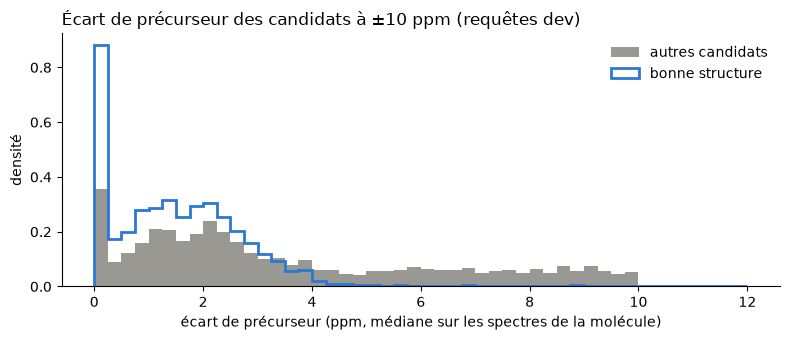

Écart médian : 1.4 ppm pour la bonne structure, 2.6 ppm pour les autres candidats


In [32]:
start = time.time()
t = table("dev", 10)
print(f"Table dev à 10 ppm : {len(t['row']):,} couples (requête, candidat), construite en {time.time() - start:.0f} s")

control = {}
for name in CATALOGUES:
    base = -np.abs(cat_masses[t["row"]] - queries["neutral_mass"].to_numpy()[t["query"]])
    control[name] = {"baseline 0, evaluate": baseline_mrr[name], "baseline 0, version rapide": mrr(t, score=base, catalogue=name),
                     "oracle, evaluate": oracle_mrr[name], "oracle, version rapide": mrr(t, true_fps, catalogue=name)}
    assert abs(control[name]["baseline 0, version rapide"] - baseline_mrr[name]) < 1e-3
    assert abs(control[name]["oracle, version rapide"] - oracle_mrr[name]) < 1e-3
display(pd.DataFrame(control).round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 12, 49)
ax.hist(t["gap_ppm"][~t["is_true"]], bins=bins, density=True, color="#9a9893", label="autres candidats")
ax.hist(t["gap_ppm"][t["is_true"]], bins=bins, density=True, histtype="step", linewidth=2, color="#2a78d6",
        label="bonne structure")
ax.set_xlabel("écart de précurseur (ppm, médiane sur les spectres de la molécule)")
ax.set_ylabel("densité")
ax.set_title("Écart de précurseur des candidats à ±10 ppm (requêtes dev)", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save_figure(fig, "ecart_precurseur")
plt.show()
print(f"Écart médian : {np.median(t['gap_ppm'][t['is_true']]):.1f} ppm pour la bonne structure, "
      f"{np.median(t['gap_ppm'][~t['is_true']]):.1f} ppm pour les autres candidats")

## 10. Criblage : la grille croisée sur 50 000 spectres

Chaque modèle est entraîné sur toutes les combinaisons de sa grille, avec 50 000 spectres tirés dans l'échantillon de la section 7 et 3 époques pour les réseaux. Chaque réglage est noté au MRR@25 sur les molécules `dev`, avec le catalogue principal à ±10 ppm et le Tanimoto seul.

| Modèle | Hyperparamètres croisés | Entraînements |
|---|---|---|
| kNN | largeur de case {0,01 ; 0,1 ; 1 Da} × intensités {aucune, racine, log}, puis k ∈ {5, 10, 15, 20, 50} sans refaire la recherche | 9 |
| Régression logistique | largeur de case {0,1 ; 1 Da} × intensités {racine, log} × adduct {one-hot, décomposé} | 8 |
| MLP | idem | 8 |
| Forêt aléatoire | largeur de case {0,1 ; 1 Da} × intensités {racine, log} | 4 |
| DreaMS + kNN | k ∈ {5, 10, 15, 20, 50}, sans refaire la recherche | 1 |
| DreaMS + tête | tête {régression logistique, MLP} | 2 |

Les deux modèles DreaMS n'ont ni largeur de case ni transformation : ils lisent le spectre brut. Ils ne sont entraînés que si les vecteurs DreaMS sont là (section 8).

Certains hyperparamètres sont fixés, pour tenir dans le budget de 2 h :
- le seuil de nettoyage reste à 0,75 Da (voir « Décisions de nettoyage », section 3) ;
- les cases de 0,01 Da sont réservées au kNN : les réseaux et la forêt auraient 100 000 entrées ;
- 3 époques suffisent pour comparer des réglages : lors de tests précédents, externes au notebook, la loss du MLP ne gagnait plus qu'environ 0,001 par époque après la 3e ;
- la tolérance (10 ou 20 ppm) et le poids de l'écart de précurseur ne demandent pas de réentraîner : ils sont testés aux sections 11 et 12.

Comptez environ 45 minutes. Chaque ligne affichée donne la durée du réglage, son MRR@25 (le meilleur k pour le kNN) et le temps écoulé depuis le début du notebook.

In [33]:
from itertools import product

N_SCREEN = 50_000               # spectres du criblage, tirés dans l'échantillon de la section 7
EPOCHS_SCREEN = 3               # époques des réseaux pendant le criblage
K_VALUES = [5, 10, 15, 20, 50]  # nombres de voisins du kNN, testés sans refaire la recherche
screen_ids = np.sort(np.random.default_rng(SEED).choice(train_ids, N_SCREEN, replace=False))
SETUP_MINUTES = elapsed()  # durée des sections 1 à 9 : données, catalogue, tables de candidats

def grid(**values):
    """Toutes les combinaisons des valeurs données (produit cartésien), une par dictionnaire."""
    return [dict(zip(values, combo)) for combo in product(*values.values())]

GRIDS = {
    "kNN": grid(bin_width=[0.01, 0.1, 1], transform=["aucune", "racine", "log"]),
    "Régression logistique": grid(bin_width=[0.1, 1], transform=["racine", "log"], adduct_encoding=["onehot", "decompose"]),
    "MLP": grid(bin_width=[0.1, 1], transform=["racine", "log"], adduct_encoding=["onehot", "decompose"]),
    "Forêt aléatoire": grid(bin_width=[0.1, 1], transform=["racine", "log"]),
}
if DREAMS_READY:  # vecteurs DreaMS calculés sur Colab (section 8)
    GRIDS["DreaMS + kNN"] = [{}]
    GRIDS["DreaMS + tête"] = grid(tête=["régression logistique", "MLP"])
print(f"{sum(map(len, GRIDS.values()))} entraînements, sur {len(reference_ids(screen_ids)):,} spectres gardés par le nettoyage")

32 entraînements, sur 49,468 spectres gardés par le nettoyage


In [34]:
screen_rows = []
for model, configs in GRIDS.items():
    print(model)
    for config in configs:
        out, seconds = run("criblage", model, config, screen_ids, ["dev"], EPOCHS_SCREEN)
        scores = {k: mrr(table("dev"), predicted_fps(model, out["dev"], "dev", k))
                  for k in (K_VALUES if model in KNN_MODELS else [None])}
        screen_rows += [{"modèle": model, "config": config, **config, "k": k, "MRR@25": score, "durée (min)": seconds / 60}
                        for k, score in scores.items()]
        print(f"  {config} : {seconds / 60:.1f} min, MRR@25 = {max(scores.values()):.3f} ; {elapsed():.0f} min écoulées")
        gc.collect()
screen = pd.DataFrame(screen_rows).astype({"k": "Int64"})
for h in ["bin_width", "transform", "adduct_encoding", "tête"]:  # hyperparamètres absents de certains modèles
    if h not in screen:
        screen[h] = None

kNN
  {'bin_width': 0.01, 'transform': 'aucune'} : 0.4 min, MRR@25 = 0.300 ; 2 min écoulées
  {'bin_width': 0.01, 'transform': 'racine'} : 0.4 min, MRR@25 = 0.376 ; 2 min écoulées
  {'bin_width': 0.01, 'transform': 'log'} : 0.4 min, MRR@25 = 0.427 ; 2 min écoulées
  {'bin_width': 0.1, 'transform': 'aucune'} : 0.6 min, MRR@25 = 0.238 ; 3 min écoulées
  {'bin_width': 0.1, 'transform': 'racine'} : 0.6 min, MRR@25 = 0.310 ; 3 min écoulées
  {'bin_width': 0.1, 'transform': 'log'} : 0.6 min, MRR@25 = 0.354 ; 3 min écoulées
  {'bin_width': 1, 'transform': 'aucune'} : 0.7 min, MRR@25 = 0.230 ; 3 min écoulées
  {'bin_width': 1, 'transform': 'racine'} : 0.7 min, MRR@25 = 0.289 ; 3 min écoulées
  {'bin_width': 1, 'transform': 'log'} : 0.7 min, MRR@25 = 0.332 ; 3 min écoulées
Régression logistique
  {'bin_width': 0.1, 'transform': 'racine', 'adduct_encoding': 'onehot'} : 1.9 min, MRR@25 = 0.104 ; 3 min écoulées
  {'bin_width': 0.1, 'transform': 'racine', 'adduct_encoding': 'decompose'} : 1.8 min, 

### Résultats du criblage

Un tableau par modèle donne le MRR@25 sur `dev` de chaque combinaison, puis le dernier tableau résume le meilleur réglage de chaque modèle et la durée de toute sa grille.

Constat :
- le kNN est de loin le meilleur : 0,427 avec des cases de 0,01 Da, des intensités en log et k = 5. Ses trois réglages comptent, et toujours dans le même sens. Des cases plus fines aident (meilleur score de 0,427 à 0,01 Da, 0,354 à 0,1 Da et 0,332 à 1 Da). Le log bat la racine, qui bat l'absence de transformation, pour chaque largeur de case. Et peu de voisins valent mieux que beaucoup : k = 5 est le meilleur pour les neuf combinaisons, et k = 50 fait tomber le meilleur réglage à 0,329 ;
- DreaMS + kNN arrive deuxième, avec 0,256 à k = 5, sans rien apprendre sur nos données ;
- la forêt (0,133 à 0,138), le MLP (0,114 à 0,119), DreaMS + tête (0,112 avec la régression logistique, 0,126 avec le MLP) et la régression logistique (0,103 à 0,107) font tous moins bien que la baseline 0 (0,172) avec le Tanimoto seul. La baseline 0 trie par écart de masse, une information que le Tanimoto seul ignore, alors que la bonne structure est en général plus proche en masse que les autres candidats (1,4 ppm contre 2,6 ppm en médiane, section 9) ; la section 11 ajoute cet écart au Tanimoto. Pour eux, ni la largeur des cases, ni la transformation, ni l'encodage de l'adduct ne changent le score de plus de 0,005 ;
- toute la grille a pris 25 minutes, dont 8 pour la régression logistique, le modèle le plus lent : ses 10 000 entrées reliées directement aux 2 048 bits font plus de poids que le MLP.

Le kNN gagne sans doute parce qu'il recopie les fingerprints de vraies molécules proches, bits rares compris. Pour les réseaux, notre hypothèse, non testée ici, est que la BCE, calculée bit par bit, leur fait apprendre surtout les bits fréquents, que partagent la plupart des candidats de même masse.

In [35]:
LAYOUT = {"kNN": (["bin_width", "transform"], "k"),  # lignes, colonnes de chaque tableau
          "Régression logistique": (["bin_width", "transform"], "adduct_encoding"),
          "MLP": (["bin_width", "transform"], "adduct_encoding"),
          "Forêt aléatoire": (["bin_width"], "transform"),
          "DreaMS + kNN": (["modèle"], "k"),
          "DreaMS + tête": (["tête"], "modèle")}
for model, (index, columns) in LAYOUT.items():
    if model in GRIDS:
        print(model)
        display(screen[screen["modèle"] == model].pivot_table(index=index, columns=columns, values="MRR@25").round(3))

best = (screen.sort_values("MRR@25", ascending=False, kind="stable").drop_duplicates("modèle")
        .set_index("modèle").loc[list(GRIDS)])
HYPERPARAMETERS = ["bin_width", "transform", "adduct_encoding", "tête"]
durations = (screen.drop_duplicates(["modèle", *HYPERPARAMETERS]).groupby("modèle")["durée (min)"].sum())
save_table(screen.drop(columns="config"), "criblage")
best_table = best[[*HYPERPARAMETERS, "k", "MRR@25"]].assign(**{"durée de la grille (min)": durations}).round(3)
save_table(best_table, "criblage_meilleurs")
best_table

kNN


k                       5      10     15     20     50
bin_width transform                                   
0.01      aucune     0.300  0.296  0.290  0.281  0.257
          log        0.427  0.420  0.402  0.387  0.329
          racine     0.376  0.374  0.363  0.350  0.304
0.10      aucune     0.238  0.216  0.200  0.193  0.169
          log        0.354  0.320  0.300  0.281  0.241
          racine     0.310  0.285  0.260  0.247  0.210
1.00      aucune     0.230  0.201  0.182  0.174  0.151
          log        0.332  0.299  0.275  0.259  0.212
          racine     0.289  0.266  0.236  0.225  0.182

Régression logistique


adduct_encoding      decompose  onehot
bin_width transform                   
0.1       log            0.107   0.105
          racine         0.106   0.104
1.0       log            0.104   0.103
          racine         0.104   0.103

MLP


adduct_encoding      decompose  onehot
bin_width transform                   
0.1       log            0.116   0.117
          racine         0.116   0.119
1.0       log            0.114   0.116
          racine         0.114   0.115

... (3 outputs left out)

k,5,10,15,20,50
modèle,,,,,
DreaMS + kNN,0.256,0.24,0.23,0.22,0.196


DreaMS + tête


modèle,DreaMS + tête
tête,
MLP,0.126
régression logistique,0.112


,bin_width,transform,adduct_encoding,tête,k,MRR@25,durée de la grille (min)
modèle,,,,,,,
kNN,0.01,log,NaN,NaN,5,0.427,5.008
Régression logistique,0.10,log,decompose,NaN,<NA>,0.107,8.227
MLP,0.10,racine,onehot,NaN,<NA>,0.119,6.916
Forêt aléatoire,1.00,racine,NaN,NaN,<NA>,0.138,4.180
DreaMS + kNN,NaN,NaN,NaN,NaN,5,0.256,0.361
DreaMS + tête,NaN,NaN,NaN,MLP,<NA>,0.126,0.666


Le graphique place chaque réglage du criblage sur la ligne de son modèle ; pour les kNN, chaque valeur de k compte comme un réglage. Le point foncé est le meilleur réglage du modèle.

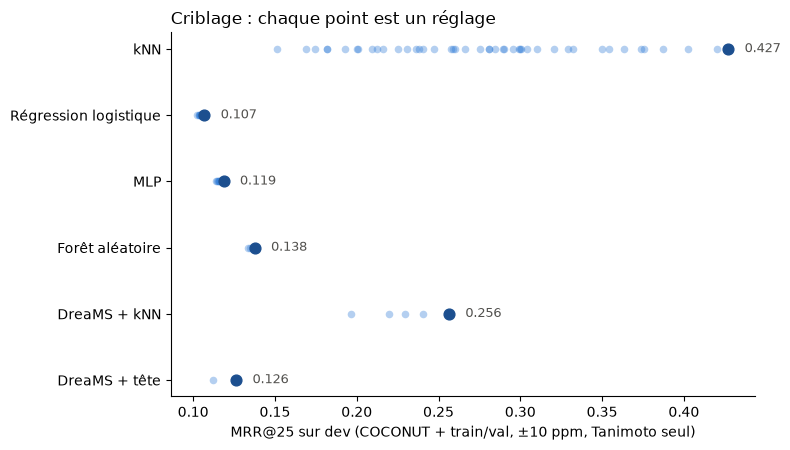

In [36]:
models = list(GRIDS)
fig, ax = plt.subplots(figsize=(8, 0.6 * len(models) + 1))
for y, model in enumerate(models):
    scores = screen.loc[screen["modèle"] == model, "MRR@25"]
    ax.scatter(scores, np.full(len(scores), y), s=30, color="#2a78d6", alpha=0.35, linewidths=0)
    ax.scatter(scores.max(), y, s=60, color="#1c4f8f", zorder=3)
    ax.text(scores.max() + 0.01, y, f"{scores.max():.3f}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(models)), models)
ax.invert_yaxis()
ax.set_xlabel("MRR@25 sur dev (COCONUT + train/val, ±10 ppm, Tanimoto seul)")
ax.set_title("Criblage : chaque point est un réglage", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save_figure(fig, "criblage")
plt.show()

## 11. Score combiné : Tanimoto et écart de précurseur

On classe maintenant les candidats avec Tanimoto − λ × écart de précurseur (en ppm). λ = 0 redonne le Tanimoto seul ; λ = 0,01 retire 0,1 de Tanimoto à un candidat à 10 ppm. Pour le meilleur réglage de chaque modèle (section 10), on teste plusieurs λ sur `dev`, à partir des prédictions du criblage déjà enregistrées. Le λ retenu pour chaque modèle sera appliqué tel quel à la confirmation.

Constat : l'écart de précurseur aide tous les modèles, et surtout les plus faibles. La régression logistique passe de 0,107 à 0,191, la forêt de 0,138 à 0,216, le MLP de 0,119 à 0,200 et DreaMS + tête de 0,126 à 0,206. Le kNN passe de 0,427 à 0,468, et DreaMS + kNN de 0,256 à 0,315. Le meilleur λ est 0,01 ou 0,02 pour tous les modèles. Au-delà, l'écart de masse pèse trop face au Tanimoto et le score redescend : le kNN tombe à 0,405 avec λ = 0,1.

In [37]:
LAMBDAS = [0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]  # Tanimoto retiré par ppm d'écart
lambda_scores = {}
for model, row in best.iterrows():
    out, _ = run("criblage", model, row["config"], screen_ids, ["dev"], EPOCHS_SCREEN)  # relu sur le disque
    pred = predicted_fps(model, out["dev"], "dev", int(row["k"]) if model in KNN_MODELS else None)
    lambda_scores[model] = {lam: mrr(table("dev"), pred, lam=lam) for lam in LAMBDAS}
lambda_scores = pd.DataFrame(lambda_scores).rename_axis("λ")
best_lambda = lambda_scores.idxmax()
print("λ retenu :", {model: float(lam) for model, lam in best_lambda.items()})
save_table(lambda_scores, "lambda")
lambda_scores.round(3)

λ retenu : {'kNN': 0.01, 'Régression logistique': 0.01, 'MLP': 0.02, 'Forêt aléatoire': 0.02, 'DreaMS + kNN': 0.02, 'DreaMS + tête': 0.02}


,kNN,Régression logistique,MLP,Forêt aléatoire,DreaMS + kNN,DreaMS + tête
λ,,,,,,
0.000,0.427,0.107,0.119,0.138,0.256,0.126
0.002,0.446,0.168,0.147,0.170,0.279,0.156
0.005,0.463,0.188,0.173,0.196,0.300,0.180
0.010,0.468,0.191,0.188,0.211,0.313,0.196
0.020,0.463,0.189,0.200,0.216,0.315,0.206
0.050,0.441,0.186,0.198,0.212,0.299,0.202
0.100,0.405,0.184,0.196,0.208,0.284,0.200


## 12. Confirmation : 200 000 spectres et 2 000 nouvelles molécules

Le meilleur réglage de chaque modèle est réentraîné sur les 200 000 spectres de l'échantillon (après nettoyage), avec 8 époques, comme lors des tests précédents, externes au notebook. Il prédit les molécules `dev` et les 2 000 molécules `confirmation`. Le réglage, k et λ ont été choisis sur `dev` : le score `dev` est donc un peu optimiste. Le score `confirmation` échappe à ce biais de sélection, mais garde les deux biais optimistes de l'évaluation (section 4) : des requêtes d'environ 9 spectres, contre 3,0 dans le test fourni, et un catalogue principal qui contient toujours la bonne structure. Comptez environ 40 minutes.

In [38]:
EPOCHS_FINAL = 8  # comme lors des tests précédents, externes au notebook
final = {}
for model, row in best.iterrows():
    print(model, row["config"])
    out, seconds = run("confirmation", model, row["config"], train_ids, ["dev", "confirmation"], EPOCHS_FINAL)
    k = int(row["k"]) if model in KNN_MODELS else None
    final[model] = {"secondes": seconds, **{s: predicted_fps(model, out[s], s, k) for s in ["dev", "confirmation"]}}
    print(f"  {seconds / 60:.1f} min ; {elapsed():.0f} min écoulées")
    gc.collect()

kNN {'bin_width': 0.01, 'transform': 'log'}
  3.2 min ; 4 min écoulées
Régression logistique {'bin_width': 0.1, 'transform': 'log', 'adduct_encoding': 'decompose'}
  18.8 min ; 4 min écoulées
MLP {'bin_width': 0.1, 'transform': 'racine', 'adduct_encoding': 'onehot'}
  12.3 min ; 4 min écoulées
Forêt aléatoire {'bin_width': 1, 'transform': 'racine'}
  5.6 min ; 4 min écoulées
DreaMS + kNN {}
  2.6 min ; 4 min écoulées
DreaMS + tête {'tête': 'MLP'}
  3.9 min ; 4 min écoulées


### Résultats

Pour chaque modèle, le tableau donne son réglage et son score au criblage, puis ses scores après réentraînement : sur `dev`, puis sur `confirmation` avec le Tanimoto seul, avec l'écart de précurseur, et sur COCONUT seule. L'intervalle de confiance à 95 % vient d'un bootstrap sur les 2 000 molécules de confirmation : 1 000 tirages avec remise, les mêmes pour tous les modèles. La baseline 0 et l'oracle encadrent les résultats.

Constat :
- le kNN (cases de 0,01 Da, log, k = 5) avec l'écart de précurseur obtient 0,576 sur les molécules de confirmation, avec un intervalle de confiance à 95 % de [0,558 ; 0,594] : trois fois la baseline 0 (0,184). Viennent ensuite DreaMS + kNN (0,389), le MLP (0,297), DreaMS + tête (0,276), la régression logistique (0,245) et la forêt (0,227). L'oracle reste à 0,977 ;
- l'intervalle du kNN ne recoupe pas celui de DreaMS + kNN [0,371 ; 0,407] : l'écart est réel. Ceux du MLP [0,281 ; 0,312] et de DreaMS + tête [0,260 ; 0,292] se recoupent : ces deux modèles ne se distinguent pas vraiment ;
- passer de 50 000 à 200 000 spectres (et à 8 époques pour les réseaux) aide tous les modèles sur `dev` : le kNN passe de 0,427 à 0,531, le MLP de 0,119 à 0,228, DreaMS + kNN de 0,256 à 0,342. La forêt gagne le moins (de 0,138 à 0,151) ;
- les scores `dev` et `confirmation` sont proches, à 0,01 près au plus (kNN : 0,531 et 0,541) : les réglages choisis sur `dev` ne sont pas sur-ajustés ;
- sur la confirmation, l'écart de précurseur apporte de 0,035 (kNN) à 0,079 (forêt). Sans lui, la régression logistique (0,173) et la forêt (0,148) restent sous la baseline 0 ; avec lui, tous les modèles la dépassent ;
- avec COCONUT seule, aucun modèle ne dépasse 0,042 (kNN), pour un oracle à 0,077 : ce catalogue ne contient presque jamais la bonne structure.

In [39]:
N_BOOT = 1_000
t_dev, t_conf = table("dev"), table("confirmation")
boot = np.random.default_rng(SEED).integers(0, t_conf["n_queries"], (N_BOOT, t_conf["n_queries"]))  # mêmes tirages pour tous

def interval(rr):
    """Intervalle de confiance à 95 % du MRR, par bootstrap sur les molécules."""
    return np.percentile(rr[boot].mean(axis=1), [2.5, 97.5])

rr_conf, rows = {}, {}
for model, f in final.items():
    lam, r = best_lambda[model], best.loc[model]
    rr_conf[model] = reciprocal_ranks(t_conf, f["confirmation"], lam=lam)
    low, high = interval(rr_conf[model])
    setting = [f"{h} = {v}" for h, v in r["config"].items()] + ([f"k = {r['k']}"] if model in KNN_MODELS else [])
    rows[model] = {"réglage": ", ".join(setting),
                   "λ": lam, "criblage (dev)": r["MRR@25"], "dev": mrr(t_dev, f["dev"]),
                   "confirmation": mrr(t_conf, f["confirmation"]), "confirmation + écart": rr_conf[model].mean(),
                   "IC 95 %": f"[{low:.3f} ; {high:.3f}]",
                   "COCONUT seule + écart": mrr(t_conf, f["confirmation"], lam=lam, catalogue="COCONUT seule"),
                   "entraînement (min)": f["secondes"] / 60}

references = {"Baseline 0 (tri par masse)": {"score": -np.abs(cat_masses[t_conf["row"]] - queries_conf["neutral_mass"].to_numpy()[t_conf["query"]])},
              "Oracle (vrai fingerprint)": {"pred": fingerprints(cat_row[queries_conf["inchikey14"]].to_numpy())}}
for name, kwargs in references.items():
    rr_conf[name] = reciprocal_ranks(t_conf, **kwargs)
    low, high = interval(rr_conf[name])
    rows[name] = {"confirmation": rr_conf[name].mean(), "IC 95 %": f"[{low:.3f} ; {high:.3f}]",
                  "COCONUT seule + écart": mrr(t_conf, catalogue="COCONUT seule", **kwargs)}
results = pd.DataFrame(rows).T.infer_objects()
save_table(results, "confirmation")
results.round(3)

,réglage,λ,criblage (dev),dev,confirmation,confirmation + écart,IC 95 %,COCONUT seule + écart,entraînement (min)
kNN,"bin_width = 0.01, transform = log, k = 5",0.01,0.427,0.531,0.541,0.576,[0.558 ; 0.594],0.042,3.189
Régression logistique,"bin_width = 0.1, transform = log, adduct_encod...",0.01,0.107,0.172,0.173,0.245,[0.230 ; 0.260],0.028,18.773
MLP,"bin_width = 0.1, transform = racine, adduct_en...",0.02,0.119,0.228,0.232,0.297,[0.281 ; 0.312],0.033,12.342
Forêt aléatoire,"bin_width = 1, transform = racine",0.02,0.138,0.151,0.148,0.227,[0.212 ; 0.242],0.028,5.589
DreaMS + kNN,k = 5,0.02,0.256,0.342,0.343,0.389,[0.371 ; 0.407],0.040,2.644
DreaMS + tête,tête = MLP,0.02,0.126,0.205,0.207,0.276,[0.260 ; 0.292],0.031,3.927
Baseline 0 (tri par masse),NaN,NaN,NaN,NaN,0.184,NaN,[0.172 ; 0.198],0.026,NaN
Oracle (vrai fingerprint),NaN,NaN,NaN,NaN,0.977,NaN,[0.971 ; 0.983],0.077,NaN


Le graphique reprend la colonne « confirmation + écart » avec son intervalle de confiance. Les lignes pointillées marquent la baseline 0 et l'oracle.

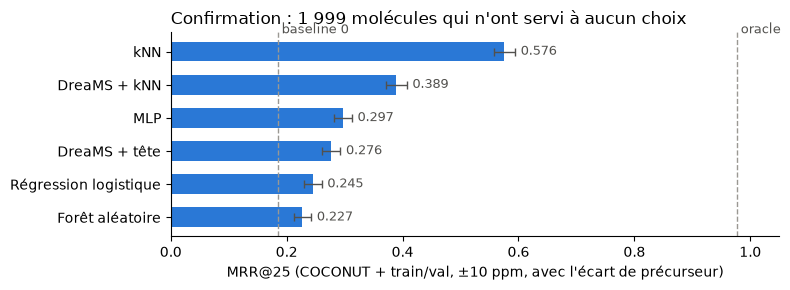

In [40]:
models = list(final)
order = sorted(models, key=lambda m: rr_conf[m].mean())
means = np.array([rr_conf[m].mean() for m in order])
ci = np.array([interval(rr_conf[m]) for m in order])

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(order, means, height=0.6, color="#2a78d6",
        xerr=[means - ci[:, 0], ci[:, 1] - means], error_kw={"ecolor": "#52514e", "capsize": 3, "linewidth": 1})
for name, label in [("Baseline 0 (tri par masse)", "baseline 0"), ("Oracle (vrai fingerprint)", "oracle")]:
    x = rr_conf[name].mean()
    ax.axvline(x, color="#9a9893", linestyle="--", linewidth=1)
    ax.text(x, len(order) - 0.45, f" {label}", color="#52514e", fontsize=9)
for y, (m, high) in enumerate(zip(means, ci[:, 1])):  # valeur écrite au-delà de la barre d'erreur
    ax.text(high + 0.01, y, f"{m:.3f}", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_xlabel("MRR@25 (COCONUT + train/val, ±10 ppm, avec l'écart de précurseur)")
ax.set_title(f"Confirmation : {t_conf['n_queries']:,} molécules qui n'ont servi à aucun choix".replace(",", " "), loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save_figure(fig, "confirmation")
plt.show()

On compare enfin deux tolérances : mêmes modèles et même λ, avec les candidats à ±10 ppm et à ±20 ppm, sur les molécules de confirmation.

Constat : ±20 ppm donne le même score qu'à ±10 ppm, à 0,001 près, pour tous les modèles. Avec l'écart de précurseur, les candidats ajoutés entre 10 et 20 ppm sont pénalisés et ne remontent pas dans le top 25. Lors de tests précédents, externes au notebook, sans cette feature, ±20 ppm faisait perdre des points. On garde ±10 ppm, qui donne deux fois moins de candidats.

In [41]:
tolerance = pd.DataFrame({f"±{ppm} ppm": {m: mrr(table("confirmation", ppm), f["confirmation"], lam=best_lambda[m])
                                          for m, f in final.items()}
                          for ppm in PPM_VALUES})
save_table(tolerance, "tolerance")
tolerance.round(3)

,±10 ppm,±20 ppm
kNN,0.576,0.575
Régression logistique,0.245,0.245
MLP,0.297,0.297
Forêt aléatoire,0.227,0.227
DreaMS + kNN,0.389,0.390
DreaMS + tête,0.276,0.276


## 13. Conclusion

La comparaison montre six choses :
- Toute la difficulté est de prédire le fingerprint : avec le vrai fingerprint, l'oracle classe la bonne structure presque toujours première (0,977).
- Le meilleur modèle est le plus simple : un kNN sur les spectres binés à 0,01 Da, avec les intensités en log et 5 voisins. Avec l'écart de précurseur, il obtient 0,576 sur 2 000 molécules qui n'ont servi à aucun choix, trois fois la baseline 0.
- Les réglages qui comptent sont ceux du kNN : des cases fines, le log et peu de voisins. Pour les réseaux et la forêt, aucun réglage testé ne change le score de plus de 0,005 : leur limite est ailleurs. Pour les réseaux, notre hypothèse, non testée ici, est la BCE, qui leur fait apprendre surtout les bits fréquents.
- La nouvelle feature, l'écart entre le précurseur mesuré et le précurseur calculé de chaque candidat, est le gain le moins cher : de 0,035 à 0,08 selon le modèle, sans réentraîner, et elle rend inutile d'élargir la tolérance à ±20 ppm.
- DreaMS, utilisé tel quel sans voir nos données, se place deuxième (0,389) avec un simple kNN sur ses vecteurs, loin devant les réseaux entraînés sur nos spectres binés. Il reste derrière le kNN à 0,01 Da, qui compare des pics précis.
- Plus de données aide : de 50 000 à 200 000 spectres, le kNN gagne 0,10.

Elle a aussi quatre limites :
- Le score principal est optimiste : le catalogue principal contient toujours la bonne structure, puisqu'il inclut les molécules de la compétition. COCONUT ne contient que 9,6 % des molécules `dev` : pour une molécule absente du jeu de données, simulée par COCONUT seule, aucun modèle ne dépasse 0,042. Il faudrait une bibliothèque bien plus large, comme PubChem.
- Les requêtes de validation comptent environ 9 spectres en moyenne, contre 3,0 dans le test fourni : leur masse médiane et leur prédiction moyennée sont probablement plus sûres, et leur score un peu flatteur. Cet effet n'est pas mesuré ici.
- Les modèles n'apprennent que sur 200 000 des 2,26 millions de spectres d'entraînement, pour tenir sur un portable. Des tests précédents, externes au notebook, montraient qu'un kNN gagne nettement avec la base complète (de 0,572 à 0,657).
- DreaMS est utilisé sans réentraînement : l'ajuster à nos données demanderait un GPU et bien plus de temps.

Le calcul complet a pris 77 minutes sur un portable sans GPU (Intel i5-1135G7, 15 Go de RAM), plus quelques minutes la toute première fois pour COCONUT et les fingerprints du catalogue, et le calcul des vecteurs DreaMS sur le GPU gratuit de Google Colab.

### Annexe : durées

Durée de ce passage, et durée d'entraînement de chaque modèle au criblage (toute sa grille) et à la confirmation. Un réglage relu sur le disque garde la durée de son premier calcul : si ce passage a relu les modèles, il est bien plus court qu'une exécution complète. La dernière ligne estime donc la durée d'une exécution sans cache, à partir des sections 1 à 9 de ce passage et des durées d'entraînement.

In [42]:
durees = pd.DataFrame({"criblage (min)": durations,
                       "confirmation (min)": pd.Series({m: f["secondes"] / 60 for m, f in final.items()})}).round(1)
save_table(durees, "durees")
training = durees.sum().sum()
print(f"Ce passage : {elapsed():.0f} min, dont {SETUP_MINUTES:.0f} min pour les sections 1 à 9")
print(f"Entraînement des modèles, au premier calcul : {training:.0f} min")
print(f"Exécution complète sans cache : environ {SETUP_MINUTES + training:.0f} min, plus l'évaluation "
      f"et, la toute première fois, quelques minutes pour les fingerprints du catalogue")
durees

Ce passage : 4 min, dont 2 min pour les sections 1 à 9
Entraînement des modèles, au premier calcul : 72 min
Exécution complète sans cache : environ 74 min, plus l'évaluation et, la toute première fois, quelques minutes pour les fingerprints du catalogue


,criblage (min),confirmation (min)
DreaMS + kNN,0.4,2.6
DreaMS + tête,0.7,3.9
Forêt aléatoire,4.2,5.6
MLP,6.9,12.3
Régression logistique,8.2,18.8
kNN,5.0,3.2
